# Late-delivery risk model (corrected)

This notebook keeps the original EDA and statistical-analysis workflow, then builds an **order-level late-delivery classifier**.

**What was corrected in the modeling part**
1. **Label-latency leakage** - an order's late/on-time flag is only known after it ships. Temporal CV folds and the final train/test split now leave an *embargo gap* (max real shipping days) so the model never trains on labels that were not yet observable.
2. **Feature selection is real again** - the 14 order-time candidates are tested against random *probe* columns with permutation importance on forward-time folds. Only features that beat noise are kept (the old notebook kept all 14 although 12 had exactly zero importance).
3. **Feature engineering** - a `Shipping Mode x order_hour` cross feature is built *inside* the linear model's pipeline (it cannot learn interactions on its own); tree models learn it natively.
4. **Honest baselines** - a smoothed `Shipping Mode x hour` lookup table is a model candidate and a test baseline (the old in-sample "lookup accuracy" was optimistic).
5. **Model selection** - by cross-validated log loss with the one-standard-error rule (simplest model within one SE of the best). The old notebook ranked models on metrics at a fixed 0.5 threshold, which is why results looked identical.
6. Removed the pointless 200-trial second tuning phase, fixed stale markdown, no global feature lists mutated by the ablation, all training rows used (cap raised).

Keep `DataCoSupplyChainDataset.csv` beside this notebook, or place it in the Kaggle/Colab input directory. Run cells from top to bottom.

In [1]:
import itertools
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import BayesianRidge
from sklearn.calibration import CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, log_loss, brier_score_loss, accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, ConfusionMatrixDisplay, RocCurveDisplay, roc_curve)
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PowerTransformer
from sklearn.tree import DecisionTreeClassifier
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from scipy import stats
from scipy.sparse.csgraph import connected_components
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import medcouple
from statsmodels.stats.oneway import anova_oneway

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 80
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:,.3f}'.format)
SEED, ALPHA = 42, 0.05
optuna.logging.set_verbosity(optuna.logging.WARNING)


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Works in Colab, Kaggle, or locally. Set PATH manually if your file is elsewhere.
candidates = [
    Path('/content/DataCoSupplyChainDataset.csv'),
    Path('/kaggle/input/dataco-supply-chain-dataset/DataCoSupplyChainDataset.csv'),
    Path('DataCoSupplyChainDataset.csv'),
]
PATH = next((p for p in candidates if p.exists()), None)
if PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Put DataCoSupplyChainDataset.csv beside this notebook "
        "or update PATH to its Kaggle/Colab location."
    )

df_raw = pd.read_csv(PATH, encoding='latin-1')
df = df_raw.copy()
print("Dataset Shape:", df.shape)
display(df.head(3).T)

Dataset Shape: (180519, 53)


,0,1,2
Type,DEBIT,TRANSFER,CASH
Days for shipping (real),3,5,4
Days for shipment (scheduled),4,4,4
Benefit per order,91.250,-249.090,-247.780
Sales per customer,314.640,311.360,309.720
Delivery Status,Advance shipping,Late delivery,Shipping on time
Late_delivery_risk,0,1,0
Category Id,73,73,73
Category Name,Sporting Goods,Sporting Goods,Sporting Goods
Customer City,Caguas,Caguas,San Jose


In [3]:
PLACEHOLDERS = {'', 'na', 'n/a', 'null', 'none', '?', '-', 'unknown', 'xxxxxxxxx'}

def missing_report(d):
    text = d.select_dtypes(exclude='number').astype('string')
    hidden = text.apply(lambda s: s.str.strip().str.lower().isin(PLACEHOLDERS)).sum()
    rep = pd.DataFrame({'dtype': d.dtypes.astype(str), 'unique': d.nunique(), 'nan': d.isna().sum(), 'placeholder': hidden}).fillna(0)
    rep['missing_%'] = 100 * (rep['nan'] + rep['placeholder']) / len(d)
    rep['constant'] = rep['unique'] <= 1
    return rep.sort_values('missing_%', ascending=False)

rep = missing_report(df)
rep

,dtype,unique,nan,placeholder,missing_%,constant
Customer Email,str,1,0,"180,519.000",100.000,True
Customer Password,str,1,0,"180,519.000",100.000,True
Product Description,float64,0,180519,0.000,100.000,True
Order Zipcode,float64,609,155679,0.000,86.240,False
Customer Lname,str,1109,8,0.000,0.004,False
Customer Zipcode,float64,995,3,0.000,0.002,False
Customer City,str,563,0,0.000,0.000,False
Customer Country,str,2,0,0.000,0.000,False
Category Id,int64,51,0,0.000,0.000,False
Customer Id,int64,20652,0,0.000,0.000,False


In [4]:
# Order Zipcode: 86% missing - is it random or structural?
df.groupby('Order Country')['Order Zipcode'].apply(lambda s: s.notna().mean()).loc[lambda s: s > 0]

Order Country
Estados Unidos   1.000
Name: Order Zipcode, dtype: float64

In [5]:
# 3 rows have a 'missing' Customer Zipcode because their columns are shifted (zipcode sits in State, state in City, city in Street)
df['Customer Zipcode'] = df['Customer Zipcode'].astype('Int64').astype('string').str.zfill(5)
shifted = ~df['Customer State'].fillna('').str.fullmatch('[A-Z]{2}')
display(df.loc[shifted, ['Customer City', 'Customer State', 'Customer Street', 'Customer Zipcode']])

r = df.loc[shifted].copy()
df.loc[shifted, 'Customer Zipcode'] = r['Customer State'].str.zfill(5)
df.loc[shifted, 'Customer State'] = r['Customer City']
df.loc[shifted, 'Customer City'] = r['Customer Street']
df.loc[shifted, 'Customer Street'] = 'Unknown'
df.loc[shifted, ['Customer City', 'Customer State', 'Customer Street', 'Customer Zipcode']]

,Customer City,Customer State,Customer Street,Customer Zipcode
35704,CA,95758,Elk Grove,<NA>
46440,CA,95758,Elk Grove,<NA>
82511,CA,91732,El Monte,<NA>


,Customer City,Customer State,Customer Street,Customer Zipcode
35704,Elk Grove,CA,Unknown,95758
46440,Elk Grove,CA,Unknown,95758
82511,El Monte,CA,Unknown,91732


In [6]:
# drop constant / empty columns and the structurally missing Order Zipcode
df = df.drop(columns=rep.index[rep['constant']].tolist() + ['Order Zipcode'])
df.shape

(180519, 48)

In [7]:
DATE_COLS = {'order date (DateOrders)': 'Order Date', 'shipping date (DateOrders)': 'Shipping Date'}
ID_COLS = ['Order Id', 'Order Item Id', 'Customer Id', 'Category Id']        # labels, not quantities
dtypes_before = df_raw.rename(columns=DATE_COLS).dtypes.astype(str)

df = df.rename(columns=DATE_COLS)
text_cols = df.select_dtypes(exclude='number').columns
df[text_cols] = df[text_cols].apply(lambda s: s.str.strip())
for c in DATE_COLS.values():
    df[c] = pd.to_datetime(df[c], format='%m/%d/%Y %H:%M')
df[ID_COLS] = df[ID_COLS].astype(str)
df['Order Year'] = df['Order Date'].dt.year.astype('category')
df['Late_delivery_risk'] = df['Late_delivery_risk'].astype('category')
for c in df.select_dtypes(exclude=['number', 'datetime']).columns.difference(ID_COLS):
    if df[c].nunique() < 1000:                                   # high-cardinality text stays as string
        df[c] = df[c].astype('category')
for c in ['Days for shipping (real)', 'Days for shipment (scheduled)', 'Order Item Quantity']:
    df[c] = pd.to_numeric(df[c], downcast='integer')

changed = pd.DataFrame({'before': dtypes_before, 'after': df.dtypes.astype(str)}).dropna()
changed[changed.before != changed.after]

,before,after
Category Id,int64,str
Category Name,str,category
Customer City,str,category
Customer Country,str,category
Customer Fname,str,category
Customer Id,int64,str
Customer Segment,str,category
Customer State,str,category
Customer Zipcode,float64,category
Days for shipment (scheduled),int64,int8


In [8]:
print('duplicate rows:', df.duplicated().sum(), '| duplicate Order Item Id:', df['Order Item Id'].duplicated().sum())

hashes = df.apply(lambda s: pd.util.hash_pandas_object(s, index=False).sum())
candidates = hashes[hashes.duplicated(keep='first')].index.tolist()
dup_cols = []
for c in candidates:
    prior = [p for p in df.columns[:df.columns.get_loc(c)] if hashes[p] == hashes[c]]
    if any(df[c].equals(df[p]) for p in prior):
        dup_cols.append(c)

print('exact duplicated columns:', dup_cols)
REDUNDANT = ['Department Id', 'Order Item Cardprod Id', 'Product Image']
df = df.drop_duplicates().drop(columns=[c for c in dup_cols + REDUNDANT if c in df.columns])
df.shape

duplicate rows: 0 | duplicate Order Item Id: 0
exact duplicated columns: ['Order Item Total', 'Order Profit Per Order', 'Product Card Id', 'Product Price']


(180519, 42)

In [9]:
# column groups derived from the cleaned dtypes
GEO_COLS  = ['Latitude', 'Longitude']
num_cols  = df.select_dtypes('number').columns.tolist()
cont_cols = [c for c in num_cols if df[c].nunique() > 30 and c not in GEO_COLS]       # continuous measurements
cat_cols  = [c for c in df.select_dtypes('category') if 2 <= df[c].nunique() <= 60]    # categorical variables for the tests
print('numeric   :', num_cols, '\ncontinuous:', cont_cols, '\ncategorical:', cat_cols)

numeric   : ['Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Latitude', 'Longitude', 'Order Customer Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Product Category Id'] 
continuous: ['Benefit per order', 'Sales per customer', 'Order Customer Id', 'Order Item Discount', 'Order Item Product Price', 'Order Item Profit Ratio', 'Sales', 'Product Category Id'] 
categorical: ['Type', 'Delivery Status', 'Late_delivery_risk', 'Category Name', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Name', 'Market', 'Order Region', 'Order Status', 'Shipping Mode', 'Order Year']


In [10]:
df['Customer Lname'] = df['Customer Lname'].fillna('Unknown')
print('missing cells left:', int(df.isna().sum().sum()))

# Modeling source: cleaned types/missing values, but before EDA-only capping/transforms.
# This prevents full-dataset EDA transformations from influencing the model holdout.
df_model_source = df.copy(deep=True)

missing cells left: 0


In [11]:
X = df[num_cols].astype(float).sample(min(20000, len(df)), random_state=SEED)
mask = pd.DataFrame(False, index=X.index, columns=X.columns)
mask[cont_cols] = np.random.default_rng(SEED).random((len(X), len(cont_cols))) < .10
scaler = StandardScaler().fit(X.mask(mask))

imputers = {'mean': SimpleImputer(strategy='mean'), 'median': SimpleImputer(strategy='median'),
            'KNN (k=5)': KNNImputer(n_neighbors=5), 'MICE': IterativeImputer(BayesianRidge(), max_iter=10, random_state=SEED)}
nrmse = {}
for name, imp in imputers.items():
    filled = pd.DataFrame(scaler.inverse_transform(imp.fit_transform(scaler.transform(X.mask(mask)))), index=X.index, columns=X.columns)
    nrmse[name] = {c: np.sqrt(((filled.loc[mask[c], c] - X.loc[mask[c], c]) ** 2).mean()) / X[c].std() for c in cont_cols}
nrmse = pd.DataFrame(nrmse); display(nrmse); print('best on average:', nrmse.mean().idxmin())

,mean,median,KNN (k=5),MICE
Benefit per order,0.996,1.000,0.821,0.570
Sales per customer,0.925,0.936,0.203,0.207
Order Customer Id,0.998,1.000,1.004,0.972
Order Item Discount,1.121,1.169,0.498,0.195
Order Item Product Price,1.007,1.169,0.142,0.241
Order Item Profit Ratio,0.970,1.017,0.808,0.554
Sales,0.936,0.937,0.203,0.190
Product Category Id,0.977,0.993,0.672,0.784


best on average: MICE


In [12]:
rules = {'Sales <= 0': (df['Sales'] <= 0).sum(), 'negative days': (df['Days for shipping (real)'] < 0).sum(),
         'discount > sales': (df['Order Item Discount'] > df['Sales']).sum(), 'discount rate outside [0,1]': (~df['Order Item Discount Rate'].between(0, 1)).sum()}
print(rules)

def adjusted_fences(s, k=3):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    mc = float(medcouple(s.sample(10000, random_state=SEED).to_numpy()))
    lo_exp, hi_exp = (-4, 3) if mc >= 0 else (-3, 4)
    return q1 - k * np.exp(lo_exp * mc) * iqr, q3 + k * np.exp(hi_exp * mc) * iqr

def outlier_share(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1; lo, hi = adjusted_fences(s)
    return pd.Series({'skew': s.skew(), 'IQR 1.5 (%)': 100 * ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).mean(),
                      'z > 3 (%)': 100 * ((s - s.mean()).abs() > 3 * s.std()).mean(), 'adjusted k=3 (%)': 100 * ((s < lo) | (s > hi)).mean()})
df[cont_cols].apply(outlier_share).T

{'Sales <= 0': np.int64(0), 'negative days': np.int64(0), 'discount > sales': np.int64(0), 'discount rate outside [0,1]': np.int64(0)}


,skew,IQR 1.5 (%),z > 3 (%),adjusted k=3 (%)
Benefit per order,-4.742,10.493,1.999,5.440
Sales per customer,2.888,1.076,0.264,0.257
Order Customer Id,0.489,0.664,0.874,0.000
Order Item Discount,3.040,4.175,1.167,0.074
Order Item Product Price,3.191,1.135,0.270,0.000
Order Item Profit Ratio,-2.894,9.583,3.331,0.040
Sales,2.884,0.270,0.259,0.259
Product Category Id,0.362,0.000,0.000,0.000


,values capped,%
Benefit per order,9820,5.440
Sales per customer,464,0.257
Order Customer Id,0,0.000
Order Item Discount,133,0.074
Order Item Product Price,0,0.000
Order Item Profit Ratio,72,0.040
Sales,467,0.259
Product Category Id,0,0.000


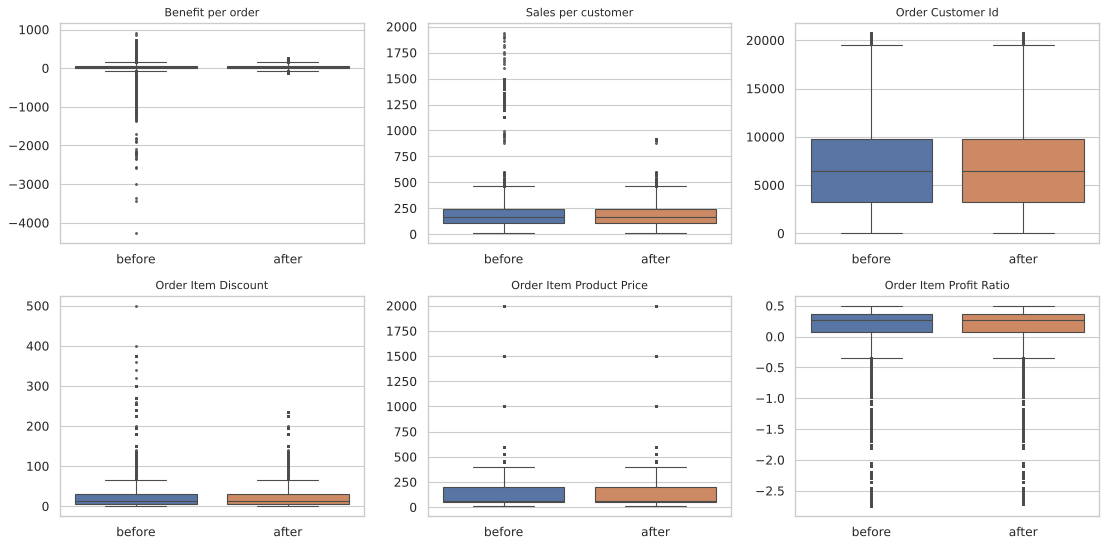

In [13]:
raw = df[cont_cols].copy()
for c in cont_cols:
    df[c] = df[c].clip(*adjusted_fences(df[c]))
capped = (raw != df[cont_cols]).sum().rename('values capped'); display(pd.concat([capped, 100 * capped / len(df)], axis=1, keys=['values capped', '%']))

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.flat, cont_cols):
    sns.boxplot(data=pd.DataFrame({'before': raw[c], 'after': df[c]}), ax=ax, fliersize=1.5); ax.set_title(c, fontsize=10)
plt.tight_layout()

In [14]:
def normality(d):
    out = pd.DataFrame({'skew': d.skew(), 'ex_kurtosis': d.kurt(),
                        'dagostino_p': d.apply(lambda s: stats.normaltest(s)[1]),
                        'shapiro_p': d.apply(lambda s: stats.shapiro(s.sample(5000, random_state=SEED))[1])})
    out['normal'] = (out['skew'].abs() < .5) & (out['ex_kurtosis'].abs() < 1)
    return out

def plot_normality(d, cols):
    fig, axes = plt.subplots(len(cols), 3, figsize=(13, 2.4 * len(cols)))
    for (h, b, q), c in zip(axes, cols):
        sns.histplot(d[c], kde=d[c].nunique() > 30, stat='density', discrete=d[c].nunique() <= 12, ax=h)
        sns.boxplot(x=d[c], ax=b, fliersize=1.5)
        stats.probplot(d[c].sample(5000, random_state=SEED), plot=q)
        h.set_title(c, fontsize=10); q.set_title('Q-Q plot', fontsize=9); q.get_lines()[1].set_color('tab:red'); h.set_xlabel(''); b.set_xlabel('')
    plt.tight_layout()

normality(df[num_cols])

,skew,ex_kurtosis,dagostino_p,shapiro_p,normal
Days for shipping (real),0.085,-1.008,0.000,0.000,False
Days for shipment (scheduled),-0.732,-1.023,0.000,0.000,False
Benefit per order,-0.408,1.203,0.000,0.000,False
Sales per customer,1.294,4.243,0.000,0.000,False
Latitude,-0.098,-1.555,0.000,0.000,False
Longitude,-0.498,2.181,0.000,0.000,False
Order Customer Id,0.489,0.015,0.000,0.000,True
Order Item Discount,2.326,11.424,0.000,0.000,False
Order Item Discount Rate,0.341,-0.901,0.000,0.000,True
Order Item Product Price,3.191,23.313,0.000,0.000,False


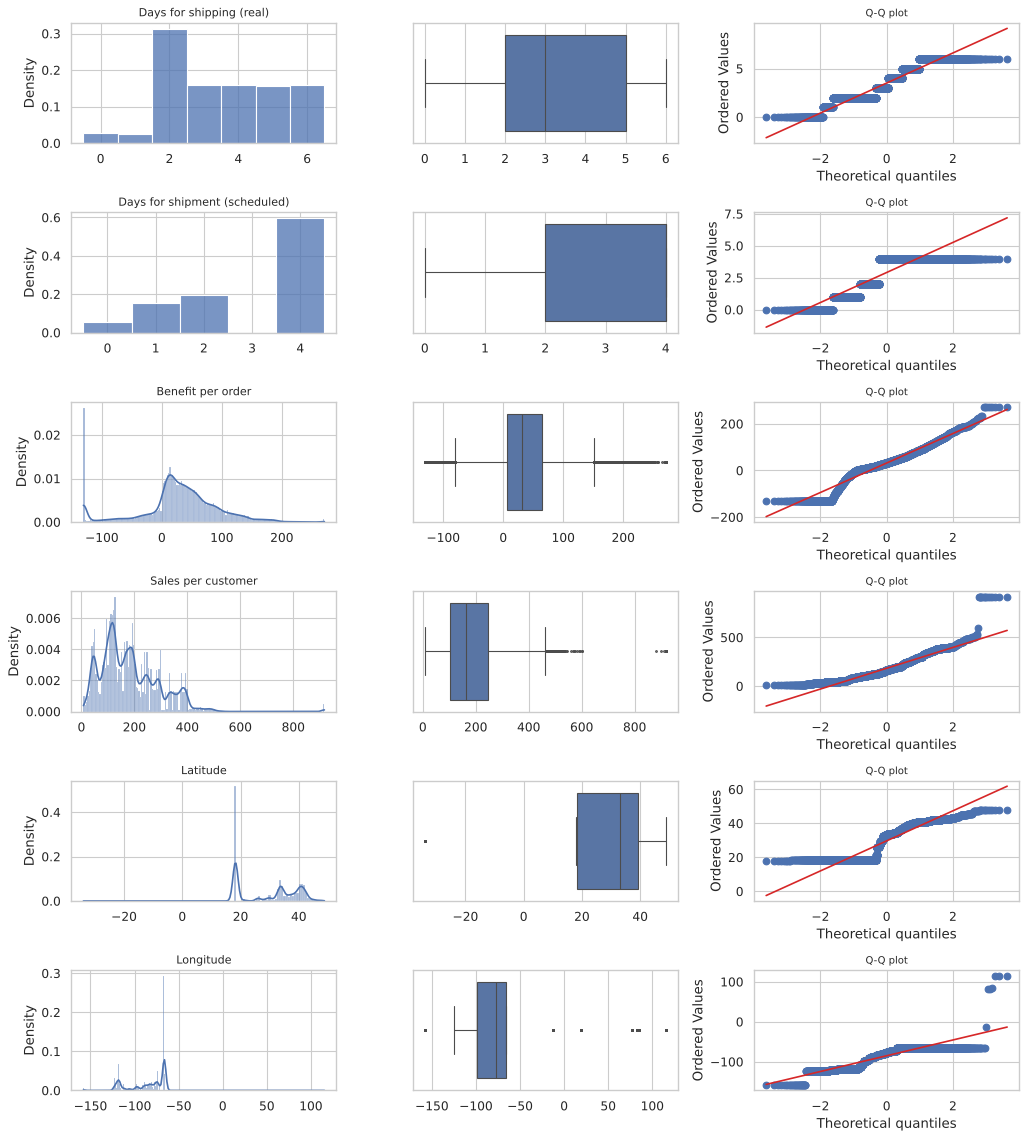

In [15]:
plot_normality(df, num_cols[:6])

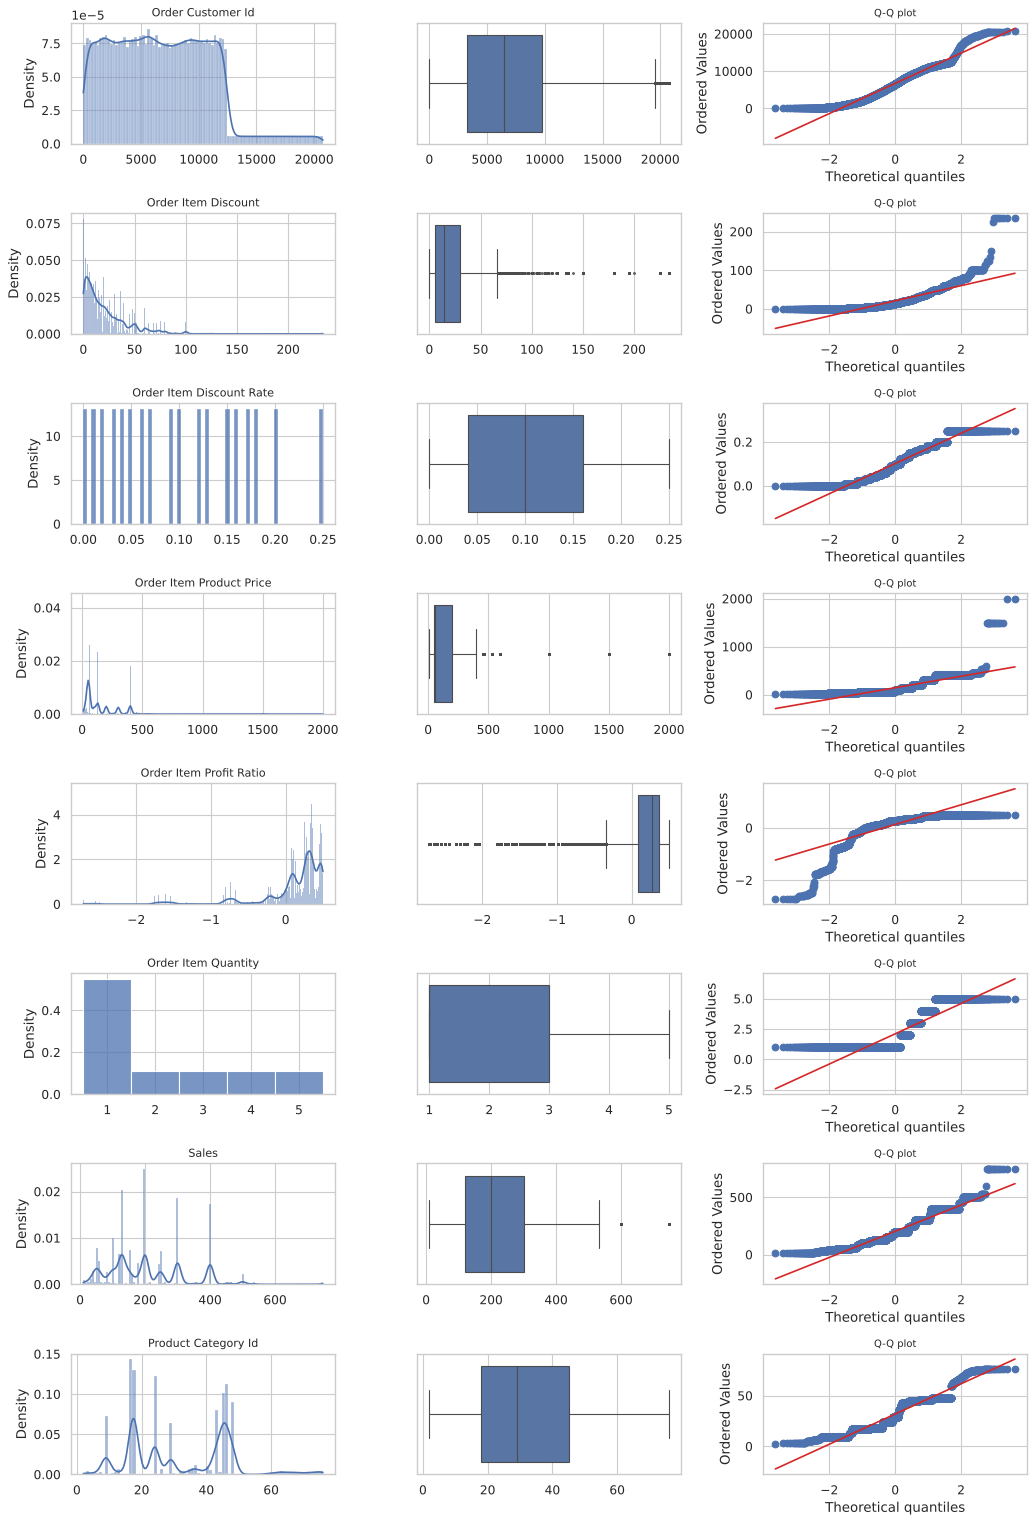

In [16]:
plot_normality(df, num_cols[6:])

,skew,ex_kurtosis,dagostino_p,shapiro_p,normal
Sales per customer_norm,-0.017,-0.125,0.000,0.000,True
Order Item Discount_norm,-0.045,-0.529,0.000,0.000,True
Order Item Product Price_norm,0.038,-0.597,0.000,0.000,True
Order Item Profit Ratio_norm,-0.282,-0.749,0.000,0.000,True
Sales_norm,-0.039,-0.421,0.000,0.000,True


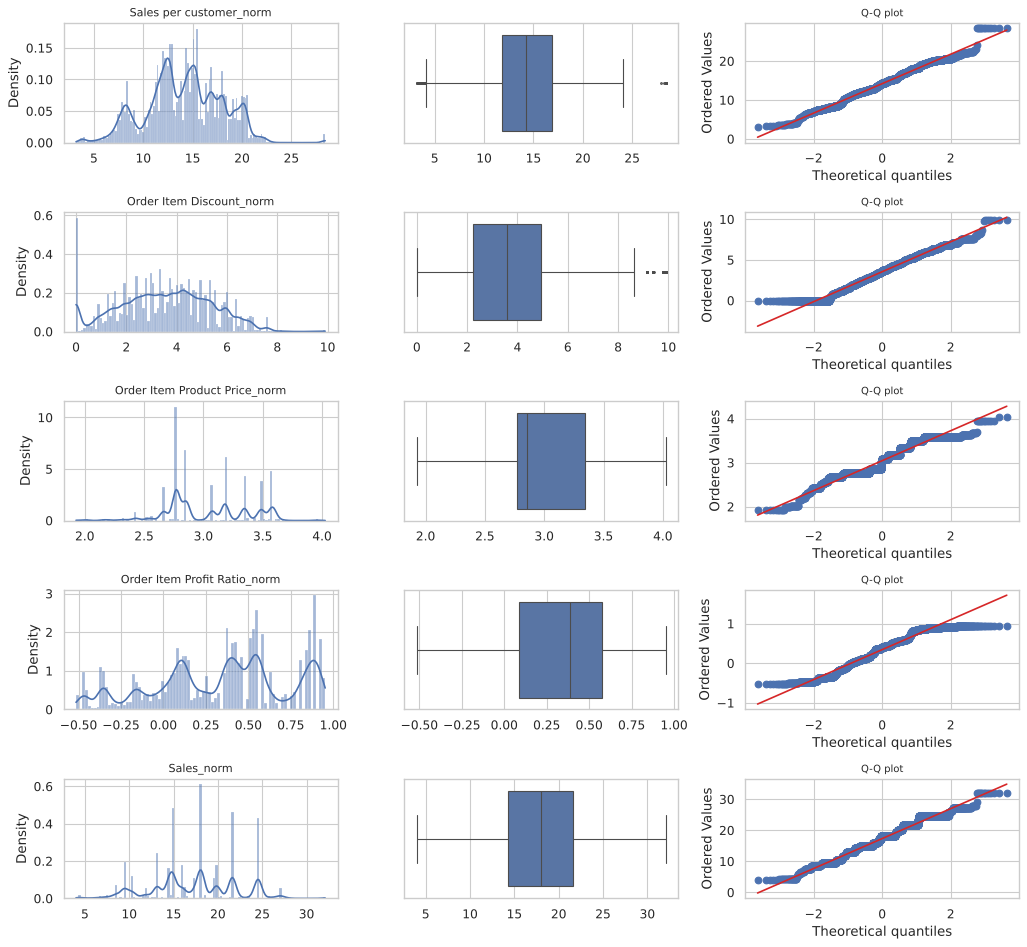

In [17]:
to_fix = [c for c in cont_cols if not normality(df[[c]]).loc[c, 'normal']]
t = pd.DataFrame(PowerTransformer(method='yeo-johnson', standardize=False).fit_transform(df[to_fix]), columns=to_fix, index=df.index)
shape = lambda d: normality(d)[['skew', 'ex_kurtosis']].abs().sum(axis=1)
improved = (shape(t) < shape(df[to_fix]))                      # keep a transform only if it really improves skew + kurtosis
norm_cols = [c + '_norm' for c in improved.index[improved]]
df[norm_cols] = t.loc[:, improved].to_numpy()
display(normality(df[norm_cols])); plot_normality(df, norm_cols)

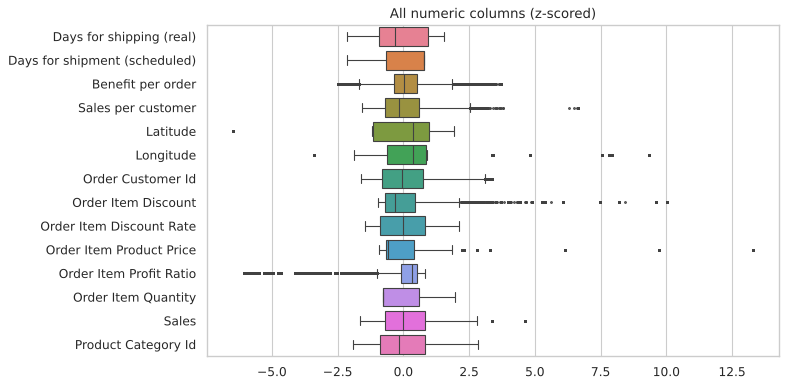

In [18]:
z = (df[num_cols] - df[num_cols].mean()) / df[num_cols].std()
plt.figure(figsize=(10, 5)); sns.boxplot(data=z, orient='h', fliersize=1.5); plt.title('All numeric columns (z-scored)'); plt.tight_layout()

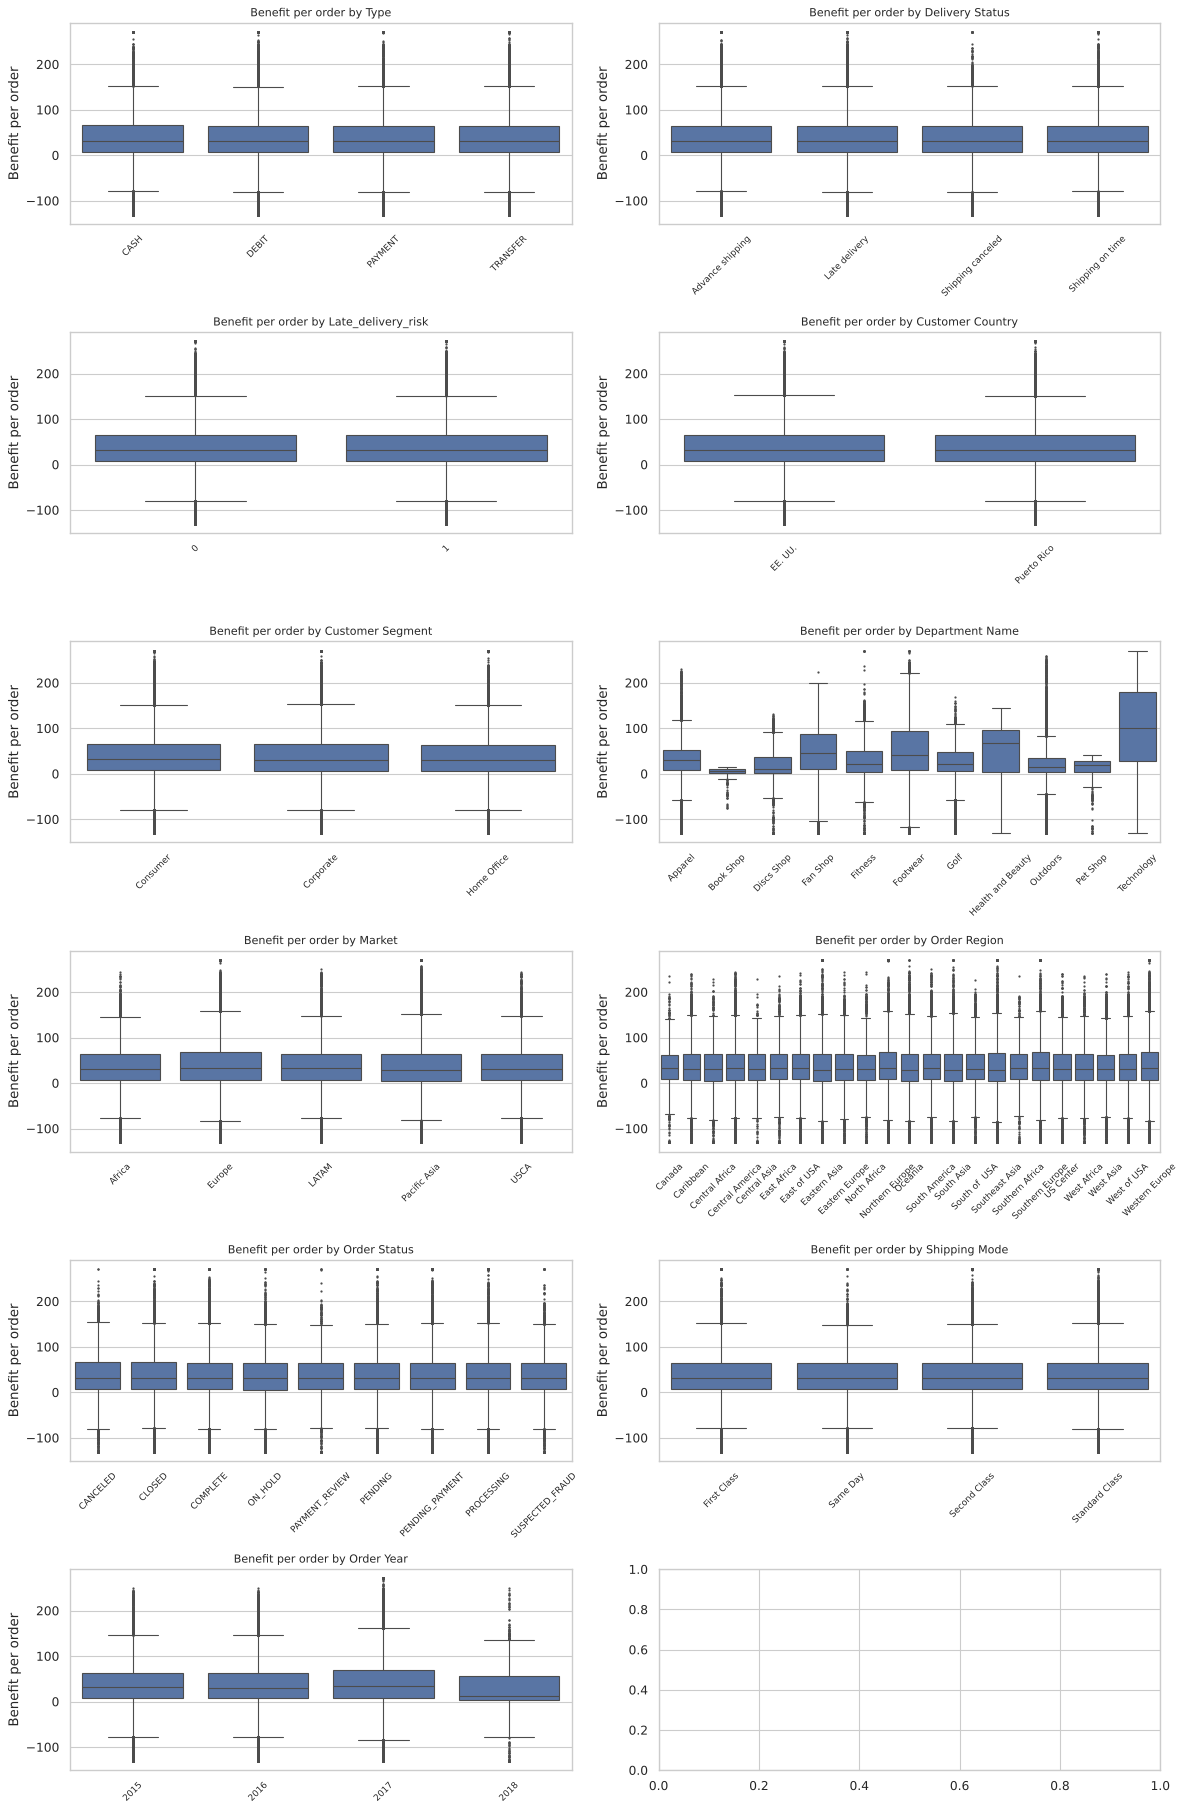

In [19]:
TARGET = 'Benefit per order'
box_cats = [c for c in cat_cols if df[c].nunique() <= 25]
fig, axes = plt.subplots(int(np.ceil(len(box_cats) / 2)), 2, figsize=(15, 3.8 * int(np.ceil(len(box_cats) / 2))))
for ax, c in zip(axes.flat, box_cats):
    sns.boxplot(data=df, x=c, y=TARGET, ax=ax, fliersize=1); ax.set_xlabel(''); ax.set_title(f'{TARGET} by {c}', fontsize=10); ax.tick_params(axis='x', rotation=45, labelsize=8)
plt.tight_layout()

In [20]:
scaled = (df[num_cols] - df[num_cols].min()) / (df[num_cols].max() - df[num_cols].min())
pd.DataFrame({'variance': df[num_cols].var(), 'CV': df[num_cols].std() / df[num_cols].mean().abs(), 'variance (min-max)': scaled.var()})

,variance,CV,variance (min-max)
Days for shipping (real),2.636,0.464,0.073
Days for shipment (scheduled),1.889,0.469,0.118
Benefit per order,"4,194.895",2.119,0.026
Sales per customer,"12,218.789",0.607,0.015
Latitude,96.308,0.330,0.014
Longitude,459.384,0.252,0.006
Order Customer Id,"17,329,887.155",0.622,0.040
Order Item Discount,452.945,1.032,0.008
Order Item Discount Rate,0.005,0.693,0.079
Order Item Product Price,"19,525.169",0.989,0.005


In [21]:
levene = [(y, g, stats.levene(*[v.values for _, v in df.groupby(g, observed=True)[y]], center='median').pvalue) for y in [TARGET] for g in box_cats]
pd.DataFrame(levene, columns=['measure', 'grouped by', 'levene_p']).assign(equal_variance=lambda t: t.levene_p > ALPHA)

,measure,grouped by,levene_p,equal_variance
0,Benefit per order,Type,0.716,True
1,Benefit per order,Delivery Status,0.701,True
2,Benefit per order,Late_delivery_risk,0.664,True
3,Benefit per order,Customer Country,0.659,True
4,Benefit per order,Customer Segment,0.667,True
5,Benefit per order,Department Name,0.000,False
6,Benefit per order,Market,0.000,False
7,Benefit per order,Order Region,0.000,False
8,Benefit per order,Order Status,0.758,True
9,Benefit per order,Shipping Mode,0.244,True


,var_1,var_2,pearson_r,pearson_p,spearman_rho,spearman_p
0,Days for shipping (real),Days for shipment (scheduled),0.516,0.000,0.500,0.000
32,Benefit per order,Order Item Profit Ratio,0.795,0.000,0.808,0.000
41,Sales per customer,Order Item Product Price,0.748,0.000,0.639,0.000
44,Sales per customer,Sales,0.983,0.000,0.986,0.000
46,Latitude,Longitude,-0.525,0.000,-0.615,0.000
70,Order Item Discount,Order Item Discount Rate,0.673,0.000,0.795,0.000
74,Order Item Discount,Sales,0.595,0.000,0.534,0.000
82,Order Item Product Price,Order Item Quantity,-0.476,0.000,-0.615,0.000
83,Order Item Product Price,Sales,0.723,0.000,0.667,0.000


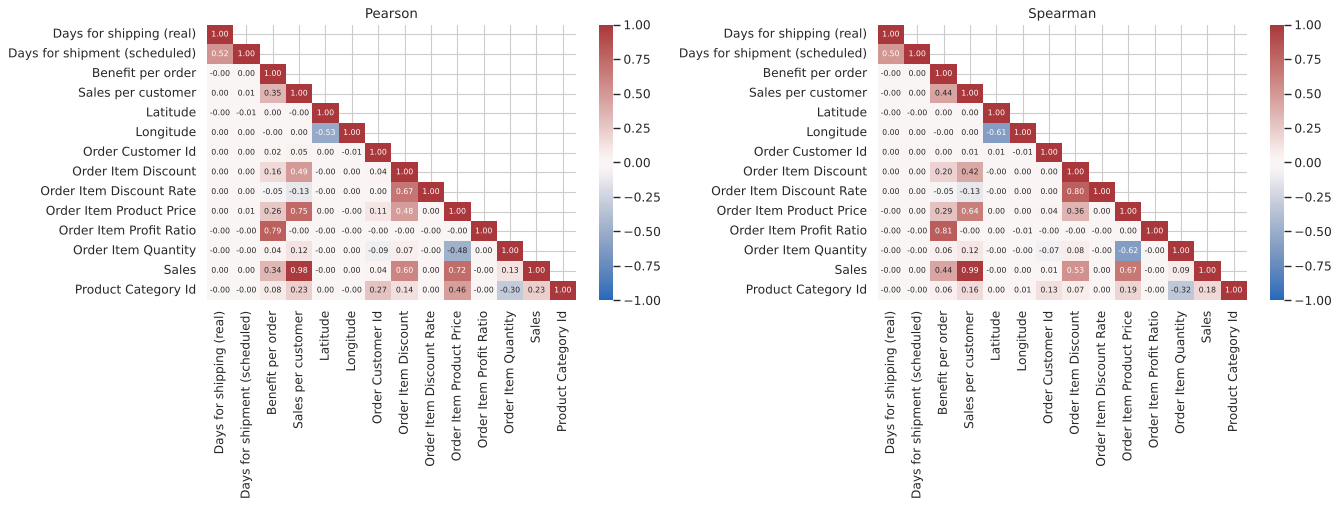

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, method in zip(axes, ['pearson', 'spearman']):
    sns.heatmap(df[num_cols].corr(method), annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1,
                mask=np.triu(np.ones((len(num_cols),) * 2, bool), 1), annot_kws={'size': 7}, ax=ax); ax.set_title(method.title())
plt.tight_layout()

pairs = pd.DataFrame([(a, b, *stats.pearsonr(df[a], df[b]), *stats.spearmanr(df[a], df[b])) for a, b in itertools.combinations(num_cols, 2)],
                     columns=['var_1', 'var_2', 'pearson_r', 'pearson_p', 'spearman_rho', 'spearman_p'])
pairs[pairs[['pearson_r', 'spearman_rho']].abs().max(axis=1) > .5]

In [23]:
def vif(X):
    # Drop zero variance columns to prevent division by zero
    X = X.loc[:, X.var() > 0]
    # Standardize columns
    Z = (X - X.mean()) / X.std()
    # Add a tiny amount of diagonal regularization to guarantee SVD convergence
    Z_val = Z.values + np.random.default_rng(SEED).normal(0, 1e-9, Z.shape)
    Z_const = sm.add_constant(Z_val)
    vifs = []
    for i in range(1, Z_const.shape[1]):
        try:
            vifs.append(variance_inflation_factor(Z_const, i))
        except Exception:
            vifs.append(np.inf)
    return pd.Series(vifs, index=X.columns)

X, dropped = df[num_cols].copy(), []
vif_before = vif(X)
while True:
    v = vif(X)
    if v.max() > 10:
        max_col = v.idxmax()
        dropped.append(max_col)
        X = X.drop(columns=max_col)
    else:
        break

display(pd.DataFrame({'VIF before': vif_before, 'VIF after': vif(X)})); print('dropped:', dropped)

,VIF before,VIF after
Benefit per order,4.037,4.018
Days for shipment (scheduled),1.363,1.363
Days for shipping (real),1.363,1.363
Latitude,1.381,1.381
Longitude,1.381,1.381
Order Customer Id,1.101,1.083
Order Item Discount,7.759,5.603
Order Item Discount Rate,3.844,3.531
Order Item Product Price,20.257,8.300
Order Item Profit Ratio,3.553,3.542


dropped: ['Sales per customer']


/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3

/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3

/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3

/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3

/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3

/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3

... (2 outputs left out)

/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3

/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3

/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3

/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]


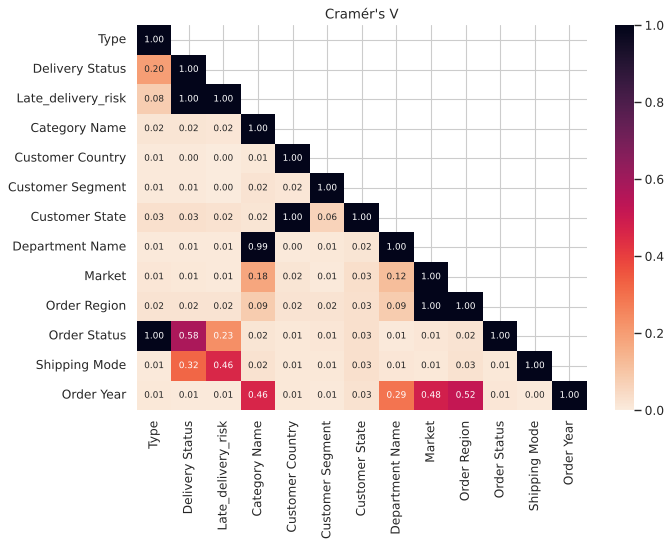

In [24]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
    chi2, p, _, _ = stats.chi2_contingency(ct, correction=False)
    return np.sqrt(chi2 / ct.values.sum() / (min(ct.shape) - 1)), p

V = pd.DataFrame({b: {a: cramers_v(df[a], df[b])[0] for a in cat_cols} for b in cat_cols})
plt.figure(figsize=(9, 7)); sns.heatmap(V, annot=True, fmt='.2f', cmap='rocket_r', vmin=0, vmax=1, mask=np.triu(np.ones(V.shape, bool), 1), annot_kws={'size': 8})
plt.title("Cramér's V"); plt.tight_layout()

In [25]:
# variables tested against each other (roles are NOT fixed here - the tests decide what is dependent / independent)
ORDER_CATS = ['Type', 'Customer Segment', 'Market', 'Order Region', 'Order Status', 'Shipping Mode',
              'Delivery Status', 'Late_delivery_risk', 'Order Year']
ORDER_AGG  = {'Sales': 'sum', 'Benefit per order': 'sum', 'Order Item Quantity': 'sum', 'Order Item Discount Rate': 'mean',
              'Days for shipping (real)': 'first', 'Days for shipment (scheduled)': 'first'}   # numeric -> one value per order
orders = df.groupby('Order Id').agg({**{c: 'first' for c in ORDER_CATS}, **ORDER_AGG})
orders[ORDER_CATS] = orders[ORDER_CATS].astype(str)
print(orders.shape); orders.head(3)

(65752, 15)


,Type,Customer Segment,Market,Order Region,Order Status,Shipping Mode,Delivery Status,Late_delivery_risk,Order Year,Sales,Benefit per order,Order Item Quantity,Order Item Discount Rate,Days for shipping (real),Days for shipment (scheduled)
Order Id,,,,,,,,,,,,,,,
1,CASH,Consumer,LATAM,Central America,CLOSED,Standard Class,Advance shipping,0,2015,299.980,88.790,1,0.200,2,4
10,PAYMENT,Corporate,LATAM,South America,PENDING_PAYMENT,Standard Class,Late delivery,1,2015,651.920,93.680,6,0.158,6,4
100,TRANSFER,Home Office,LATAM,Caribbean,PROCESSING,Second Class,Late delivery,1,2015,549.940,-49.060,6,0.090,6,2


In [26]:
def compare_means(num, cat):
    groups = [x.values for _, x in orders.groupby(cat)[num]]
    skew = max(np.nan_to_num(abs(stats.skew(a)), nan=np.inf) for a in groups)      # constant group -> treated as not normal
    levene_p = stats.levene(*groups, center='median').pvalue
    h, p_kw = stats.kruskal(*groups)
    if skew < 1:
        equal = levene_p > ALPHA
        return ('ANOVA' if equal else 'Welch ANOVA'), np.sqrt(h / (len(orders) - 1)), anova_oneway(groups, use_var='equal' if equal else 'unequal').pvalue
    return 'Kruskal-Wallis', np.sqrt(h / (len(orders) - 1)), p_kw

def association(a, b):
    if a in ORDER_CATS and b in ORDER_CATS:
        v, p = cramers_v(orders[a], orders[b]); return 'chi-square', v, p
    if a in ORDER_AGG and b in ORDER_AGG:
        r, p = stats.spearmanr(orders[a], orders[b]); return 'Spearman', abs(r), p
    return compare_means(*((b, a) if a in ORDER_CATS else (a, b)))

variables = ORDER_CATS + list(ORDER_AGG)
dep = pd.DataFrame([(a, b, *association(a, b)) for a, b in itertools.combinations(variables, 2)], columns=['var_1', 'var_2', 'test', 'strength', 'p_value'])
dep['conclusion'] = np.select([dep.p_value >= ALPHA, dep.strength >= .10], ['independent', 'dependent'], 'significant but negligible')
display(dep.conclusion.value_counts())
dep.sort_values('strength', ascending=False)

/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3

/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3

/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3

/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3

/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3

/tmp/ipykernel_174/3229354053.py:3: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  skew = max(np.nan_to_num(abs(stats.skew(a)), nan=np.inf) for a in groups)      # constant group -> treated as not normal
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3324408130.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
/tmp/ipykernel_174/3229354053.py:3: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  skew = max(np.nan_to_num(abs(stats.skew(a)), nan=np.inf) for a in gro

conclusion
independent                   65
dependent                     27
significant but negligible    13
Name: count, dtype: int64

,var_1,var_2,test,strength,p_value,conclusion
3,Type,Order Status,chi-square,1.000,0.000,dependent
27,Market,Order Region,chi-square,1.000,0.000,dependent
68,Shipping Mode,Days for shipment (scheduled),Kruskal-Wallis,1.000,0.000,dependent
69,Delivery Status,Late_delivery_risk,chi-square,1.000,0.000,dependent
91,Sales,Order Item Quantity,Spearman,0.742,0.000,dependent
...,...,...,...,...,...,...
93,Sales,Days for shipping (real),Spearman,0.002,0.698,independent
24,Customer Segment,Order Item Discount Rate,ANOVA,0.001,0.871,independent
80,Late_delivery_risk,Order Item Quantity,ANOVA,0.001,0.999,independent
81,Late_delivery_risk,Order Item Discount Rate,ANOVA,0.001,0.873,independent


In [27]:
link = pd.DataFrame(0, variables, variables)
for a, b in dep.loc[dep.conclusion == 'dependent', ['var_1', 'var_2']].itertuples(index=False):
    link.loc[a, b] = link.loc[b, a] = 1
_, label = connected_components(link.values)
groups = pd.Series(variables).groupby(label).agg(list)
display(pd.DataFrame({'members': groups, 'size': groups.str.len(), 'role': np.where(groups.str.len() > 1, 'dependent group', 'independent variable')}))

,members,size,role
0,"[Type, Order Status, Shipping Mode, Delivery S...",7,dependent group
1,[Customer Segment],1,independent variable
2,"[Market, Order Region, Order Year, Sales, Bene...",6,dependent group
3,[Order Item Discount Rate],1,independent variable


In [28]:
group_of = pd.Series(label, index=variables)
inside = dep[dep.var_1.map(group_of) == dep.var_2.map(group_of)].assign(group=lambda t: t.var_1.map(group_of))
inside.sort_values(['group', 'strength'], ascending=[True, False])

,var_1,var_2,test,strength,p_value,conclusion,group
3,Type,Order Status,chi-square,1.000,0.000,dependent,0
68,Shipping Mode,Days for shipment (scheduled),Kruskal-Wallis,1.000,0.000,dependent,0
69,Delivery Status,Late_delivery_risk,chi-square,1.000,0.000,dependent,0
67,Shipping Mode,Days for shipping (real),Kruskal-Wallis,0.626,0.000,dependent,0
51,Order Status,Delivery Status,chi-square,0.577,0.000,dependent,0
104,Days for shipping (real),Days for shipment (scheduled),Spearman,0.499,0.000,dependent,0
76,Delivery Status,Days for shipment (scheduled),Kruskal-Wallis,0.461,0.000,dependent,0
61,Shipping Mode,Late_delivery_risk,chi-square,0.456,0.000,dependent,0
75,Delivery Status,Days for shipping (real),Kruskal-Wallis,0.396,0.000,dependent,0
83,Late_delivery_risk,Days for shipment (scheduled),Kruskal-Wallis,0.388,0.000,dependent,0


In [29]:
for gid, members in groups[groups.str.len() > 1].items():
    nums, cats = [m for m in members if m in ORDER_AGG], [m for m in members if m in ORDER_CATS]
    print(f'---- group {gid}: means of {nums} by {cats}')
    display(pd.concat({c: orders.groupby(c)[nums].mean() for c in cats}))

---- group 0: means of ['Days for shipping (real)', 'Days for shipment (scheduled)'] by ['Type', 'Order Status', 'Shipping Mode', 'Delivery Status', 'Late_delivery_risk']


Days for shipping (real)  \
Type               CASH                                  3.479   
                   DEBIT                                 3.503   
                   PAYMENT                               3.521   
                   TRANSFER                              3.490   
Order Status       CANCELED                              3.464   
                   CLOSED                                3.479   
                   COMPLETE                              3.500   
                   ON_HOLD                               3.518   
                   PAYMENT_REVIEW                        3.476   
                   PENDING                               3.493   
                   PENDING_PAYMENT                       3.523   
                   PROCESSING                            3.489   
                   SUSPECTED_FRAUD                       3.509   
Shipping Mode      First Class                           2.000   
                   Same Day                              0.484   
                   Second Class                          4.002   
                   Standard Class                        3.997   
Delivery Status    Advance shipping                      2.497   
                   Late delivery                         4.092   
                   Shipping canceled                     3.487   
                   Shipping on time                      2.981   
Late_delivery_risk 0                                     2.783   
                   1                                     4.092   

                                      Days for shipment (scheduled)  
Type               CASH                                       2.923  
                   DEBIT                                      2.938  
                   PAYMENT                                    2.937  
                   TRANSFER                                   2.931  
Order Status       CANCELED                                   2.897  
                   CLOSED                                     2.923  
                   COMPLETE                                   2.934  
                   ON_HOLD                                    2.961  
                   PAYMENT_REVIEW                             2.884  
                   PENDING                                    2.936  
                   PENDING_PAYMENT                            2.939  
                   PROCESSING                                 2.937  
                   SUSPECTED_FRAUD                            2.909  
Shipping Mode      First Class                                1.000  
                   Same Day                                   0.000  
                   Second Class                               2.000  
                   Standard Class                             4.000  
Delivery Status    Advance shipping                           4.000  
                   Late delivery                              2.474  
                   Shipping canceled                          2.903  
                   Shipping on time                           2.981  
Late_delivery_risk 0                                          3.493  
                   1                                          2.474

---- group 2: means of ['Sales', 'Benefit per order', 'Order Item Quantity'] by ['Market', 'Order Region', 'Order Year']


Sales  Benefit per order  Order Item Quantity
Market       Africa          595.343             89.877                6.643
             Europe          570.424             87.451                5.670
             LATAM           598.196             90.414                6.574
             Pacific Asia    466.775             69.409                4.761
             USCA            590.573             90.158                6.599
Order Region Canada          604.728             97.434                7.065
             Caribbean       588.389             87.712                6.488
             Central Africa  588.603             86.849                6.655
             Central America 602.992             90.880                6.608
             Central Asia    596.956             91.168                6.598
             East Africa     613.760             95.153                6.604
             East of USA     590.233             91.141                6.504
             Eastern Asia    440.722             64.690                4.328
             Eastern Europe  599.278             87.017                6.816
             North Africa    596.572             85.590                6.725
             Northern Europe 563.406             87.043                5.490
             Oceania         460.425             68.094                4.684
             South America   594.674             91.058                6.557
             South Asia      462.712             69.136                4.685
             South of  USA   584.226             90.221                6.546
             Southeast Asia  437.592             66.617                4.324
             Southern Africa 573.496             95.022                6.299
             Southern Europe 561.449             87.114                5.511
             US Center       595.016             90.744                6.705
             West Africa     595.218             90.663                6.699
             West Asia       580.945             84.474                6.537
             West of USA     589.207             88.003                6.579
             Western Europe  572.482             87.778                5.645
Order Year   2015            590.357             88.271                6.625
             2016            589.857             87.863                6.585
             2017            523.847             81.895                4.853
             2018            156.218             22.504                1.000

In [30]:
# categorical pair example: late-delivery risk by shipping mode (rows add up to 1)
pd.crosstab(orders['Shipping Mode'], orders['Late_delivery_risk'], normalize='index').rename(columns={'0': 'on time', '1': 'late risk'})

Late_delivery_risk,on time,late risk
Shipping Mode,,
First Class,0.047,0.953
Same Day,0.539,0.461
Second Class,0.233,0.767
Standard Class,0.619,0.381


In [31]:
df.to_csv('DataCo_cleaned.csv', index=False)

In [32]:
# EDA wrote DataCo_cleaned.csv for inspection. Modeling starts from the uncapped
# cleaned copy saved before EDA-only outlier capping and power transformations.
df = df_model_source.copy(deep=True)
df.shape

(180519, 42)

In [33]:
# Extra imports / helpers for the modeling part
from math import sqrt
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import average_precision_score, matthews_corrcoef, fbeta_score, confusion_matrix

MAX_TRAIN_ROWS = 60_000     # effectively "use everything"; lower it only if runtime is a problem
N_TRIALS = 50               # Optuna trials per model family (phase 1)
N_TRIALS_BEST = 100         # extra trials for the best model (phase 2)


def cap_train_indices(indices, seed, cap=None):
    cap = MAX_TRAIN_ROWS if cap is None else cap
    indices = np.asarray(indices, dtype=int)
    if len(indices) > cap:
        indices = np.sort(np.random.default_rng(seed).choice(indices, size=cap, replace=False))
    return indices


class LookupClassifier(ClassifierMixin, BaseEstimator):
    """Smoothed group-rate table. keys=('Shipping Mode', 'order_hour') gives a hierarchical estimate:
    prior -> mode rate -> mode x hour rate, each level shrunk toward its parent with strength `shrink`."""
    def __init__(self, keys=('Shipping Mode', 'order_hour'), shrink=20.0):
        self.keys = keys
        self.shrink = shrink

    def _cols(self, X):
        return [X[k].astype(str).to_numpy() for k in self.keys]

    def fit(self, X, y):
        y = np.asarray(y).astype(int)
        self.classes_ = np.array([0, 1])
        self.prior_ = float(y.mean())
        cols = self._cols(X)
        d = pd.DataFrame({f'k{i}': c for i, c in enumerate(cols)})
        d['y'] = y
        self.tables_ = []
        for j in range(1, len(cols) + 1):
            names = [f'k{i}' for i in range(j)]
            g = d.groupby(names)['y'].agg(['sum', 'count'])
            if j == 1:
                parent = np.full(len(g), self.prior_)
            else:
                parent = self.tables_[j - 2].reindex(g.index.droplevel(-1)).to_numpy()
            p = (g['sum'].to_numpy() + self.shrink * parent) / (g['count'].to_numpy() + self.shrink)
            self.tables_.append(pd.Series(p, index=g.index))
        return self

    def predict_proba(self, X):
        cols = self._cols(X)
        p = np.full(len(X), self.prior_)
        for j, table in enumerate(self.tables_, start=1):
            idx = pd.MultiIndex.from_arrays(cols[:j]) if j > 1 else pd.Index(cols[0])
            vals = table.reindex(idx).to_numpy(dtype=float)
            p = np.where(np.isnan(vals), p, vals)      # unseen cell -> keep the parent level's estimate
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= .5).astype(int)


## 1. Target selection
The hub should act *before* the delivery, so the question is **"will this order be late?"** - the binary flag `Late_delivery_risk` (1 = real shipping days > scheduled days). A classifier gives an actionable alert and a probability, which a day-count forecast does not.

In [34]:
TARGET = 'Late_delivery_risk'
df[TARGET] = df[TARGET].astype(int)      # plain integers: avoids categorical-dtype comparison quirks downstream
print('orders whose items disagree on the flag:', int((df.groupby('Order Id', observed=True)[TARGET].nunique() > 1).sum()))
print('late share of items:', round(df[TARGET].mean(), 3))

orders whose items disagree on the flag: 0
late share of items: 0.548


## 2. One row per order
The flag is the same for all items of an order, and the order is the unit the portal works with, so the model is built on **orders**: item rows would count each delivery several times and leak the label between items of one order.

In [35]:
cats = ['Type', 'Customer Segment', 'Market', 'Order Region', 'Order Country', 'Customer Country', 'Customer State',
        'Shipping Mode', 'Delivery Status', 'Order Status']
keep_cols = cats + [TARGET, 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Customer Id', 'Order Date', 'Shipping Date']
orders = df.groupby('Order Id', observed=True).agg(
    **{c: (c, 'first') for c in keep_cols},
    n_items=('Order Item Id', 'count'),
    total_qty=('Order Item Quantity', 'sum'),
    total_sales=('Sales', 'sum'),
    avg_discount_rate=('Order Item Discount Rate', 'mean')
).reset_index()

# A cancelled order has no completed delivery outcome. NOTE: this filter uses information that only exists after
# the order is placed, so the model estimates lateness *conditional on the order eventually shipping*.
n_cancelled = (orders['Delivery Status'] == 'Shipping canceled').sum()
orders = orders.loc[orders['Delivery Status'] != 'Shipping canceled'].copy()
print(f'Excluded cancelled orders: {n_cancelled:,}')

orders['order_hour'] = orders['Order Date'].dt.hour
orders['order_dow'] = orders['Order Date'].dt.dayofweek
orders['order_month'] = orders['Order Date'].dt.month
# only used by the leakage audit below (dropped afterwards): how long the order waited before shipping
orders['ship_lag_days'] = (orders['Shipping Date'] - orders['Order Date']).dt.total_seconds() / 86400
orders = orders.sort_values('Order Date').reset_index(drop=True)
print('Modeling orders:', orders.shape)
orders.head(3)

Excluded cancelled orders: 2,855
Modeling orders: (62897, 25)


,Order Id,Type,Customer Segment,Market,Order Region,Order Country,Customer Country,Customer State,Shipping Mode,Delivery Status,Order Status,Late_delivery_risk,Days for shipping (real),Days for shipment (scheduled),Customer Id,Order Date,Shipping Date,n_items,total_qty,total_sales,avg_discount_rate,order_hour,order_dow,order_month,ship_lag_days
0,1,CASH,Consumer,LATAM,Central America,México,EE. UU.,NC,Standard Class,Advance shipping,CLOSED,0,2,4,11599,2015-01-01 00:00:00,2015-01-03 00:00:00,1,1,299.980,0.200,0,3,1,2.000
1,2,PAYMENT,Consumer,LATAM,South America,Colombia,EE. UU.,IL,Standard Class,Advance shipping,PENDING_PAYMENT,0,3,4,256,2015-01-01 00:21:00,2015-01-04 00:21:00,3,7,579.980,0.097,0,3,1,3.000
2,4,CASH,Home Office,LATAM,South America,Colombia,EE. UU.,TX,Standard Class,Late delivery,CLOSED,1,5,4,8827,2015-01-01 01:03:00,2015-01-06 01:03:00,4,14,699.850,0.143,1,3,1,5.000


## 3. Leakage
A feature is allowed only if it is **known when the order is placed**. Three checks: leakage by definition (is a column built from the target?), a detector (how well does one column alone predict the target?), and **label latency** (when does the label itself become known?).

**Label latency / embargo.** The late flag is only observed after the order ships, up to `max(real shipping days)` days later. In production, on the day you predict, you can only train on orders that are at least that old. Every temporal split below therefore leaves an *embargo gap* between the end of training and the start of validation/test.

In [36]:
EMBARGO_DAYS = int(orders['Days for shipping (real)'].max())
print('embargo gap (days) = max real shipping days =', EMBARGO_DAYS)


def expanding_date_splits(frame, n_splits=5, min_train_fraction=0.50, embargo_days=None):
    """Expanding-window CV on whole calendar dates. Training stops `embargo_days` before each validation block."""
    embargo = pd.Timedelta(days=EMBARGO_DAYS if embargo_days is None else embargo_days)
    day = frame['Order Date'].dt.normalize()
    dates = pd.DatetimeIndex(sorted(day.unique()))
    first_valid = max(1, int(len(dates) * min_train_fraction))
    splits = []
    for pos in np.array_split(np.arange(first_valid, len(dates)), n_splits):
        if len(pos) == 0:
            continue
        block = dates[pos]
        train_dates = dates[dates < block[0] - embargo]
        if len(train_dates) == 0:
            continue
        tr = np.flatnonzero(day.isin(train_dates).to_numpy())
        va = np.flatnonzero(day.isin(block).to_numpy())
        if len(tr) and len(va) and frame[TARGET].iloc[tr].nunique() == 2 and frame[TARGET].iloc[va].nunique() == 2:
            splits.append((tr, va))
    if len(splits) < 2:
        raise ValueError('Not enough date history/classes for temporal CV. Reduce n_splits or min_train_fraction.')
    return splits

embargo gap (days) = max real shipping days = 6


In [37]:
real, sched = orders['Days for shipping (real)'], orders['Days for shipment (scheduled)']
print('Late_delivery_risk == (real > scheduled days):', ((real > sched).astype(int) == orders[TARGET]).mean())

leak_audit = orders.copy()        # keeps the leaky columns for the detector below


def single_feature_auc(d, cols):
    out = {}
    splits = expanding_date_splits(d, n_splits=3, min_train_fraction=0.50)
    for c in cols:
        x = d[[c]].copy()
        if not pd.api.types.is_numeric_dtype(x[c]):
            x[c] = x[c].astype('category').cat.codes
        scores_ = []
        for fold, (tr, va) in enumerate(splits):
            tr = cap_train_indices(tr, SEED + fold, cap=30_000)
            m = DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=SEED)
            m.fit(x.iloc[tr], d[TARGET].iloc[tr])
            scores_.append(roc_auc_score(d[TARGET].iloc[va], m.predict_proba(x.iloc[va])[:, 1]))
        out[c] = np.mean(scores_)
    return pd.Series(out, name='forward-time CV AUC of one column alone').sort_values(ascending=False)

Late_delivery_risk == (real > scheduled days): 1.0


In [38]:
LEAKY = {'Days for shipping (real)': 'the flag is defined from it (real > scheduled)',
         'Shipping Date': 'order date + real shipping days',
         'ship_lag_days': 'derived from Shipping Date',
         'Delivery Status': 'contains the outcome (Late delivery / on time / advance)',
         'Order Status': 'changes after the order is placed (cancelled, completed, ...)'}
orders = orders.drop(columns=list(LEAKY))
print('removed:', list(LEAKY))

removed: ['Days for shipping (real)', 'Shipping Date', 'ship_lag_days', 'Delivery Status', 'Order Status']


The target matches `real shipping days > scheduled days`. Delivery status, actual shipping time/date and order status are excluded because they are unavailable or reveal the outcome after checkout. Cancelled orders are excluded using their eventual status, so this estimates lateness *conditional on an order eventually shipping*; for a production decision at order placement, cancellation should be modeled as a separate outcome.

The final test set is strictly later in time **and separated from training by the embargo gap**; all model-selection folds use expanding-window temporal validation with the same gap. Customers may appear in both periods because the intended deployment predicts future orders, including repeat customers. If deployment targets unseen customers, add a separate customer-held-out evaluation.

In [39]:
# Split on complete calendar dates; training stops EMBARGO_DAYS before the test period starts.
day = orders['Order Date'].dt.normalize()
all_dates = pd.DatetimeIndex(sorted(day.unique()))
cut = all_dates[int(np.floor(len(all_dates) * 0.80)) - 1]
train = orders[day <= cut - pd.Timedelta(days=EMBARGO_DAYS)].copy()
test = orders[day > cut].copy()
print(f'train {len(train):,} orders through {train["Order Date"].max():%Y-%m-%d} | '
      f'embargo {EMBARGO_DAYS} days | test {len(test):,} orders from {test["Order Date"].min():%Y-%m-%d}')
print('gap between last train order and first test order:', (test['Order Date'].min() - train['Order Date'].max()).days, 'days')

# leakage detector on the training period only (the test period is never inspected)
leak_audit_train = leak_audit.loc[leak_audit['Order Id'].isin(train['Order Id'])]
display(single_feature_auc(leak_audit_train, leak_audit.columns.difference(
    [TARGET, 'Order Id', 'Customer Id', 'Order Date', 'Shipping Date']).tolist()).head(10))

train 48,929 orders through 2017-06-13 | embargo 6 days | test 13,672 orders from 2017-06-20
gap between last train order and first test order: 6 days


Delivery Status                 1.000
Days for shipping (real)        0.861
ship_lag_days                   0.834
Days for shipment (scheduled)   0.741
Shipping Mode                   0.741
order_hour                      0.536
order_month                     0.507
total_qty                       0.503
Market                          0.502
Order Region                    0.502
Name: forward-time CV AUC of one column alone, dtype: float64

## 4. Feature selection

**Candidates** are the 14 columns known at checkout. Before selecting, check which candidates are *functionally redundant* (one fully determines the other) - the hierarchy is empirical, not assumed.

**Selection method (no test data used).** Add random *probe* columns (four numeric and three categorical, one with 60 levels like a country) to the candidates. In every forward-time fold, fit a regularised gradient-boosting model on the earlier data and measure **permutation importance** (log-loss increase when the column is shuffled) on the later validation block. A feature is kept only if its mean importance **beats the best of the probes**, is at least a minimum practical effect (0.001 log loss) and is **positive in every fold**. This replaces both the earlier greedy forward selector (which depended on the fold/probe draw) and the "keep everything" shortcut (which kept 12 features with zero importance).

*Limitation:* permutation importance can split credit between strongly correlated features. The leave-one-out ablation in section 6 double-checks the final set.

In [40]:
pool_cat = ['Type', 'Customer Segment', 'Market', 'Order Region', 'Order Country', 'Customer State', 'Shipping Mode']
pool_num = ['n_items', 'total_qty', 'total_sales', 'avg_discount_rate', 'order_hour', 'order_dow', 'order_month']
FEATURES_ALL = pool_cat + pool_num
print(len(FEATURES_ALL), 'checkout-time candidates:', FEATURES_ALL)


def determines(a, b, d=orders):
    """True if every value of a maps to exactly one value of b."""
    return bool((d.groupby(a, observed=True)[b].nunique() <= 1).all())


print('Shipping Mode -> scheduled days :', determines('Shipping Mode', 'Days for shipment (scheduled)'))
print('scheduled days -> Shipping Mode :', determines('Days for shipment (scheduled)', 'Shipping Mode'))
print('Customer State -> Customer Country:', determines('Customer State', 'Customer Country'))
print('Order Country -> Order Region     :', determines('Order Country', 'Order Region'))
print('Order Region  -> Market           :', determines('Order Region', 'Market'))
print('-> Customer Country and scheduled days are redundant (excluded); Market / Order Region are coarser views of')
print('   Order Country, so they stay as candidates and the probe test decides whether any of them adds information.')

14 checkout-time candidates: ['Type', 'Customer Segment', 'Market', 'Order Region', 'Order Country', 'Customer State', 'Shipping Mode', 'n_items', 'total_qty', 'total_sales', 'avg_discount_rate', 'order_hour', 'order_dow', 'order_month']
Shipping Mode -> scheduled days : True
scheduled days -> Shipping Mode : True
Customer State -> Customer Country: True
Order Country -> Order Region     : False
Order Region  -> Market           : True
-> Customer Country and scheduled days are redundant (excluded); Market / Order Region are coarser views of
   Order Country, so they stay as candidates and the probe test decides whether any of them adds information.


In [41]:
# ---- probe-based, forward-time permutation-importance selection (training period only) ----
rp = np.random.default_rng(SEED)
sel = train.copy()
sel['probe_num_a'] = rp.normal(size=len(sel))                         # symmetric continuous
sel['probe_num_b'] = rp.lognormal(5, 1, len(sel))             # skewed continuous (like sales)
sel['probe_num_c'] = rp.integers(0, 24, len(sel)).astype(float)       # integer, 24 levels (like hour)
sel['probe_num_d'] = rp.integers(1, 6, len(sel)).astype(float)        # small integer (like item count)
sel['probe_cat_a'] = rp.choice(['A', 'B', 'C'], len(sel))
sel['probe_cat_b'] = rp.choice(list('ABCDEFGH'), len(sel))
sel['probe_cat_c'] = rp.choice([f'P{i:02d}' for i in range(60)], len(sel))   # high cardinality (like country)

sel_cat = pool_cat + ['probe_cat_a', 'probe_cat_b', 'probe_cat_c']
sel_num = pool_num + ['probe_num_a', 'probe_num_b', 'probe_num_c', 'probe_num_d']
sel_feats = sel_cat + sel_num

sel_cv = [(cap_train_indices(tr, SEED + i, cap=20_000), va)
          for i, (tr, va) in enumerate(expanding_date_splits(sel, n_splits=5))]
imp = {}
for i, (tr, va) in enumerate(sel_cv):
    m = Pipeline([
        ('prep', ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=20, sparse_output=False), sel_cat),
                                    ('num', 'passthrough', sel_num)])),
        ('model', HistGradientBoostingClassifier(learning_rate=.05, max_iter=150, max_depth=4, min_samples_leaf=50,
                                                 l2_regularization=1.0, random_state=SEED))])
    m.fit(sel[sel_feats].iloc[tr], sel[TARGET].iloc[tr])
    r_ = permutation_importance(m, sel[sel_feats].iloc[va], sel[TARGET].iloc[va], scoring='neg_log_loss',
                                n_repeats=5, random_state=SEED + i)
    imp[f'fold {i + 1}'] = pd.Series(r_.importances_mean, index=sel_feats)
imp = pd.DataFrame(imp)

probes = [c for c in sel_feats if c.startswith('probe_')]
MIN_EFFECT = 0.001                                   # smallest log-loss gain worth a feature (~0.15 % of a 0.68 baseline)
noise_ceiling = imp.loc[probes].mean(axis=1).max()   # best random probe
need = imp.shape[1]                                  # positive in EVERY forward fold
selection = pd.DataFrame({'mean importance': imp.mean(axis=1), 'folds > 0': (imp > 0).sum(axis=1)})
selection['beats noise'] = ((selection['mean importance'] > noise_ceiling) & (selection['mean importance'] >= MIN_EFFECT)
                            & (selection['folds > 0'] >= need))
selection = selection.sort_values('mean importance', ascending=False)
display(pd.concat([selection, imp.loc[selection.index]], axis=1))
print(f'noise ceiling (best of {len(probes)} probes): {noise_ceiling:.5f} | rule: mean > ceiling, mean >= {MIN_EFFECT}, positive in all {need} folds')

FEATURES = [c for c in FEATURES_ALL if selection.loc[c, 'beats noise']]
if not FEATURES:
    raise RuntimeError('No feature beat the probes - check the data / target.')
print('\nSELECTED FEATURES:', FEATURES)

,mean importance,folds > 0,beats noise,fold 1,fold 2,fold 3,fold 4,fold 5
Shipping Mode,0.596,5,True,0.566,0.624,0.642,0.558,0.592
order_hour,0.070,5,True,0.060,0.074,0.076,0.069,0.069
probe_num_a,0.000,4,False,0.000,-0.000,0.000,0.000,0.000
Order Country,0.000,2,False,-0.000,-0.000,-0.000,0.000,0.001
Customer State,0.000,4,False,0.000,-0.000,0.000,0.000,0.000
probe_cat_c,0.000,2,False,0.000,0.001,-0.000,-0.000,-0.000
probe_num_b,0.000,3,False,-0.000,0.001,0.000,0.000,-0.000
total_sales,0.000,2,False,-0.000,-0.000,0.000,0.001,-0.000
total_qty,0.000,4,False,0.000,0.000,0.000,-0.000,0.000
Customer Segment,0.000,3,False,-0.000,-0.000,0.000,0.000,0.000


noise ceiling (best of 7 probes): 0.00019 | rule: mean > ceiling, mean >= 0.001, positive in all 5 folds

SELECTED FEATURES: ['Shipping Mode', 'order_hour']


The importance table is data-dependent - review it after running. Features that do not beat the random probes are dropped; adding them can only add variance.

## 5. Class balance and structure of the signal
Look at the late rate by shipping mode and by mode x hour. If a few cells sit at 0 or 1, the outcome there is (almost) a deterministic function of the features, and the remaining uncertainty elsewhere is noise no model can remove.

late share 0.572 | on-time share 0.428


,late_rate,orders
Shipping Mode,,
First Class,1.000,7490
Same Day,0.467,2637
Second Class,0.799,9518
Standard Class,0.399,29284


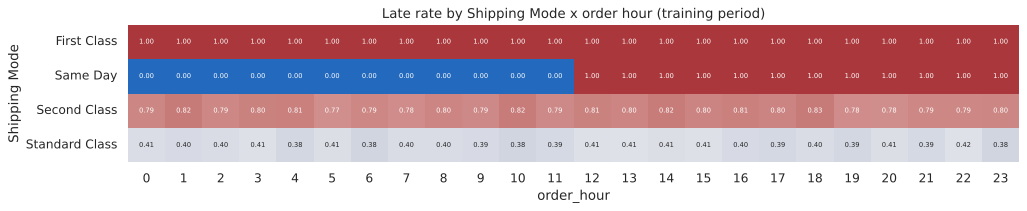

In [42]:
y = train[TARGET]
print(f'late share {y.mean():.3f} | on-time share {1 - y.mean():.3f}')
by_mode = train.groupby('Shipping Mode', observed=True)[TARGET].agg(late_rate='mean', orders='count')
display(by_mode)

grid_rate = train.pivot_table(index='Shipping Mode', columns='order_hour', values=TARGET, aggfunc='mean', observed=True)
plt.figure(figsize=(13, 2.8))
sns.heatmap(grid_rate, annot=True, fmt='.2f', cmap='vlag', center=.5, cbar=False, annot_kws={'size': 6})
plt.title('Late rate by Shipping Mode x order hour (training period)'); plt.tight_layout()

Class weighting is intentionally omitted: the late share is moderate, and probabilities are evaluated with log loss (a proper scoring rule) - re-weighting would distort them.

## 6. Model comparison
Six candidates are compared with **expanding-window temporal CV on the training period, with the embargo gap**:
a smoothed **lookup table** (the baseline any model must beat), logistic regression (with the `Shipping Mode x hour` cross built inside its pipeline), random forest, HistGradientBoosting, LightGBM and XGBoost - each tuned with Optuna (log loss). Preprocessing is fitted inside each fold. The test set is not used for any choice.

**Selection rule:** lowest CV log loss, but the *simplest* model within one standard error of the best is preferred (one-SE rule). If several families tie, the simplest one wins.

In [43]:
X_train, y_train = train[FEATURES], train[TARGET]

cv = [(cap_train_indices(tr, SEED + i), va) for i, (tr, va) in enumerate(expanding_date_splits(train, n_splits=5))]
for i, (tr, va) in enumerate(cv, 1):
    print(f'fold {i}: train {len(tr):>6,} (through {train["Order Date"].iloc[tr].max():%Y-%m-%d}) | '
          f'validate {len(va):>6,} ({train["Order Date"].iloc[va].min():%Y-%m-%d} -> {train["Order Date"].iloc[va].max():%Y-%m-%d})')


def add_cross(X):
    X = X.copy()
    X['mode_hour'] = X['Shipping Mode'].astype(str) + '_' + X['order_hour'].astype(int).astype(str)
    return X


def preprocess(feats, kind):
    cat = [c for c in feats if c in pool_cat]
    num = [c for c in feats if c in pool_num]
    cross = kind == 'linear' and {'Shipping Mode', 'order_hour'} <= set(feats)      # interaction for the linear model only
    cat_cols = cat + (['mode_hour'] if cross else [])
    parts = []
    if cat_cols:
        parts.append(('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=20, sparse_output=False), cat_cols))
    if num:
        parts.append(('num', StandardScaler() if kind == 'linear' else 'passthrough', num))
    steps = ([('cross', FunctionTransformer(add_cross))] if cross else []) + [('prep', ColumnTransformer(parts, remainder='drop'))]
    return steps


def build(name, t, feats=None):
    feats = FEATURES if feats is None else feats
    if name == 'Lookup':
        keys = tuple(c for c in ('Shipping Mode', 'order_hour') if c in feats)
        return Pipeline([('model', LookupClassifier(keys=keys, shrink=t.suggest_float('shrink', 1, 200, log=True)))])
    if name == 'LogisticRegression':
        model, kind = LogisticRegression(C=t.suggest_float('C', 1e-3, 100, log=True), max_iter=2000), 'linear'
    elif name == 'RandomForest':
        model, kind = RandomForestClassifier(n_estimators=t.suggest_int('n_estimators', 50, 200), max_depth=t.suggest_int('max_depth', 3, 14),
                                             min_samples_leaf=t.suggest_int('min_samples_leaf', 1, 100, log=True),
                                             max_features=t.suggest_float('max_features', .3, 1), n_jobs=2, random_state=SEED), 'tree'
    elif name == 'HistGradientBoosting':
        model, kind = HistGradientBoostingClassifier(learning_rate=t.suggest_float('learning_rate', .01, .3, log=True),
                                                     max_iter=t.suggest_int('max_iter', 50, 400), max_leaf_nodes=t.suggest_int('max_leaf_nodes', 4, 64),
                                                     min_samples_leaf=t.suggest_int('min_samples_leaf', 5, 200, log=True),
                                                     l2_regularization=t.suggest_float('l2_regularization', 1e-3, 10, log=True), random_state=SEED), 'tree'
    elif name == 'LightGBM':
        model, kind = LGBMClassifier(n_estimators=t.suggest_int('n_estimators', 100, 600), learning_rate=t.suggest_float('learning_rate', .01, .3, log=True),
                                     num_leaves=t.suggest_int('num_leaves', 4, 64), min_child_samples=t.suggest_int('min_child_samples', 5, 200, log=True),
                                     subsample=t.suggest_float('subsample', .5, 1), subsample_freq=1, colsample_bytree=t.suggest_float('colsample_bytree', .5, 1),
                                     reg_lambda=t.suggest_float('reg_lambda', 1e-3, 10, log=True), verbose=-1, n_jobs=2, random_state=SEED), 'tree'
    else:
        model, kind = XGBClassifier(n_estimators=t.suggest_int('n_estimators', 100, 600), learning_rate=t.suggest_float('learning_rate', .01, .3, log=True),
                                    max_depth=t.suggest_int('max_depth', 2, 8), min_child_weight=t.suggest_float('min_child_weight', 1, 100, log=True),
                                    subsample=t.suggest_float('subsample', .5, 1), colsample_bytree=t.suggest_float('colsample_bytree', .5, 1),
                                    reg_lambda=t.suggest_float('reg_lambda', 1e-3, 10, log=True), tree_method='hist', n_jobs=2, random_state=SEED), 'tree'
    return Pipeline(preprocess(feats, kind) + [('model', model)])


def run_cv(make, feats=None):
    """Forward-time CV. Returns out-of-fold probabilities (NaN before the first validation block), per-fold validation and training log loss."""
    feats = FEATURES if feats is None else feats
    Xf = train[feats]
    oof = np.full(len(train), np.nan)
    fold_loss, train_loss = [], []
    for tr, va in cv:
        m = make().fit(Xf.iloc[tr], y_train.iloc[tr])
        p = m.predict_proba(Xf.iloc[va])[:, 1]
        oof[va] = p
        fold_loss.append(log_loss(y_train.iloc[va], p, labels=[0, 1]))
        train_loss.append(log_loss(y_train.iloc[tr], m.predict_proba(Xf.iloc[tr])[:, 1], labels=[0, 1]))
    return oof, np.array(fold_loss), np.array(train_loss)


def objective(t, name):
    _, fl, tl = run_cv(lambda: build(name, t))
    t.set_user_attr('fold_std', float(np.std(fl, ddof=1)))
    t.set_user_attr('train_logloss', float(np.mean(tl)))
    return float(np.mean(fl))


MODELS = ['Lookup', 'LogisticRegression', 'RandomForest', 'HistGradientBoosting', 'LightGBM', 'XGBoost']   # simplest -> most complex

fold 1: train 24,137 (through 2016-03-16) | validate  4,881 (2016-03-23 -> 2016-06-20)
fold 2: train 29,034 (through 2016-06-14) | validate  4,906 (2016-06-21 -> 2016-09-18)
fold 3: train 33,911 (through 2016-09-12) | validate  4,930 (2016-09-19 -> 2016-12-17)
fold 4: train 38,862 (through 2016-12-11) | validate  4,860 (2016-12-18 -> 2017-03-16)


fold 5: train 43,726 (through 2017-03-10) | validate  4,882 (2017-03-17 -> 2017-06-13)


In [44]:
studies = {}
for name in MODELS:
    studies[name] = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED))
    studies[name].optimize(lambda t: objective(t, name), n_trials=N_TRIALS)
    print(f'{name:<22} best CV log loss {studies[name].best_value:.4f}')

Lookup                 best CV log loss 0.4997


LogisticRegression     best CV log loss 0.4994


RandomForest           best CV log loss 0.4990


HistGradientBoosting   best CV log loss 0.4992


LightGBM               best CV log loss 0.4993


XGBoost                best CV log loss 0.4993


In [45]:
# Phase 2: the best family from phase 1 gets N_TRIALS_BEST more trials
phase2_name = min(studies, key=lambda n: studies[n].best_value)
before = studies[phase2_name].best_value
studies[phase2_name].optimize(lambda t: objective(t, phase2_name), n_trials=N_TRIALS_BEST)
print(f'{phase2_name}: best CV log loss {before:.4f} after {N_TRIALS} trials -> {studies[phase2_name].best_value:.4f} after {len(studies[phase2_name].trials)} trials')

RandomForest: best CV log loss 0.4990 after 50 trials -> 0.4990 after 150 trials


In [46]:
# CV metrics of every model with its best parameters (threshold-free metrics decide; accuracy shown for context only)
oofs, rows = {}, []
valid_mask = np.zeros(len(train), dtype=bool)
for tr, va in cv:
    valid_mask[va] = True
yv = y_train.to_numpy()[valid_mask]

for name in MODELS:
    oof, fl, tl = run_cv(lambda: build(name, optuna.trial.FixedTrial(studies[name].best_params)))
    oofs[name] = oof
    rows.append({'Model': name, 'CV log loss': fl.mean(), 'fold std': fl.std(ddof=1), 'train log loss': tl.mean(),
                 'CV-train gap': fl.mean() - tl.mean(), 'ROC-AUC': roc_auc_score(yv, oof[valid_mask]),
                 'PR-AUC': average_precision_score(yv, oof[valid_mask]), 'Brier': brier_score_loss(yv, oof[valid_mask]),
                 'accuracy @0.5': accuracy_score(yv, oof[valid_mask] >= .5), 'trials': len(studies[name].trials)})
phase1 = pd.DataFrame(rows).set_index('Model')
display(phase1.round(4))

best_name = phase1['CV log loss'].idxmin()
se_best = phase1.loc[best_name, 'fold std'] / sqrt(len(cv))
eligible = [m for m in MODELS if phase1.loc[m, 'CV log loss'] <= phase1.loc[best_name, 'CV log loss'] + se_best]
selected = eligible[0]                              # MODELS is ordered simplest -> most complex
print(f'lowest CV log loss: {best_name} ({phase1.loc[best_name, "CV log loss"]:.4f}, SE {se_best:.4f})')
print(f'within one SE: {eligible}')
print(f'SELECTED (simplest within one SE): {selected}')
challenger = phase1.drop(index='Lookup')['CV log loss'].idxmin()      # best non-lookup model: the one that must beat the lookup
print('best non-lookup challenger:', challenger)

,CV log loss,fold std,train log loss,CV-train gap,ROC-AUC,PR-AUC,Brier,accuracy @0.5,trials
Model,,,,,,,,,
Lookup,0.500,0.002,0.500,-0.001,0.776,0.856,0.174,0.723,50
LogisticRegression,0.499,0.002,0.500,-0.001,0.776,0.856,0.174,0.723,50
RandomForest,0.499,0.002,0.500,-0.001,0.777,0.856,0.174,0.723,150
HistGradientBoosting,0.499,0.002,0.500,-0.001,0.777,0.856,0.174,0.723,50
LightGBM,0.499,0.002,0.500,-0.001,0.776,0.856,0.174,0.723,50
XGBoost,0.499,0.002,0.500,-0.001,0.776,0.856,0.174,0.723,50


lowest CV log loss: RandomForest (0.4990, SE 0.0011)
within one SE: ['Lookup', 'LogisticRegression', 'RandomForest', 'HistGradientBoosting', 'LightGBM', 'XGBoost']
SELECTED (simplest within one SE): Lookup
best non-lookup challenger: RandomForest


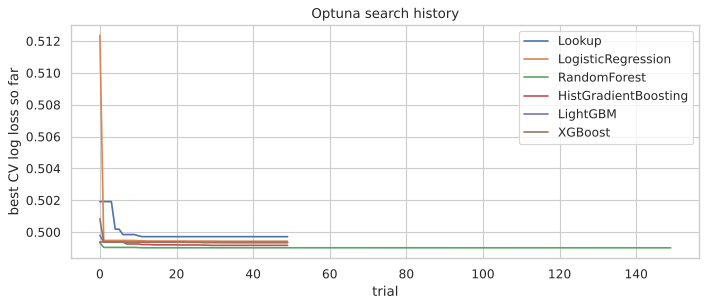

In [47]:
fig, ax = plt.subplots(figsize=(9, 4))
for n, s in studies.items():
    ax.plot(np.minimum.accumulate([t.value for t in s.trials]), label=n)
ax.set_xlabel('trial'); ax.set_ylabel('best CV log loss so far'); ax.set_title('Optuna search history'); ax.legend(); plt.tight_layout()

**Result.** Phase 1 (50 trials per family) ends with all six within 0.0007 log loss of each other (0.4990-0.4997). Phase 2 gave the best family (RandomForest) 100 more trials and its CV log loss stayed at 0.4990. The features, not the algorithm, are the limit: there is nothing left for a more complex model to learn, and extra tuning only fits noise.

In [48]:
# Ablation for the best non-lookup model, same hyper-parameters, same folds: does selection help, and is every kept feature needed?
abl_model = challenger                      # the lookup ignores extra columns, so ablate a model that really uses them
params = studies[abl_model].best_params
sets = {'selected features': FEATURES, 'all 14 candidates': FEATURES_ALL}
for f in FEATURES:
    rest = [c for c in FEATURES if c != f]
    if rest:
        sets[f'selected minus {f}'] = rest
abl = []
for label, feats in sets.items():
    oof, fl, _ = run_cv(lambda: build(abl_model, optuna.trial.FixedTrial(params), feats), feats)
    abl.append({'feature set': label, 'n features': len(feats), 'CV log loss': fl.mean(),
                'ROC-AUC': roc_auc_score(yv, oof[valid_mask]), 'PR-AUC': average_precision_score(yv, oof[valid_mask])})
display(pd.DataFrame(abl).set_index('feature set').round(4))

,n features,CV log loss,ROC-AUC,PR-AUC
feature set,,,,
selected features,2,0.499,0.777,0.856
all 14 candidates,14,0.499,0.774,0.855
selected minus Shipping Mode,1,0.680,0.535,0.598
selected minus order_hour,1,0.537,0.741,0.821


## 7. Final model, threshold and test evaluation
The alert threshold is selected from **forward, out-of-fold predictions on the training period** (balanced accuracy, middle of the best plateau); the test period is reserved for final evaluation. Baselines are fitted on the same rows and get their own forward-OOF thresholds. Customer-cluster bootstrap intervals account for repeated orders from the same customer; the *paired* AUC difference against the lookup baseline shows whether model complexity buys anything.

In [49]:
def best_threshold(oof, mask=valid_mask):
    g = np.linspace(.05, .95, 91)
    s = np.array([balanced_accuracy_score(y_train.to_numpy()[mask], oof[mask] >= v) for v in g])
    return float(np.median(g[s >= s.max() - 1e-9]))              # middle of the plateau (probabilities are often tied)


final_idx = cap_train_indices(np.arange(len(train)), SEED)
fit_rows = train.iloc[final_idx]
print(f'final models fitted on {len(final_idx):,} of {len(train):,} training orders')

models_, thrs_ = {}, {}
for name in dict.fromkeys([selected, best_name, challenger]):                 # selected model (+ the lowest-log-loss model if different)
    models_[name] = build(name, optuna.trial.FixedTrial(studies[name].best_params)).fit(fit_rows[FEATURES], fit_rows[TARGET])
    thrs_[name] = best_threshold(oofs[name])
final, thr = models_[selected], thrs_[selected]

BASE_KEYS = {'lookup: Shipping Mode': ('Shipping Mode',), 'lookup: Shipping Mode + hour': ('Shipping Mode', 'order_hour')}
for label, keys in BASE_KEYS.items():
    models_[label] = LookupClassifier(keys=keys, shrink=20.).fit(fit_rows, fit_rows[TARGET])
    oof_b, _, _ = run_cv(lambda: LookupClassifier(keys=keys, shrink=20.), list(keys))
    thrs_[label] = best_threshold(oof_b)
print('alert thresholds (forward OOF):', {k: round(v, 2) for k, v in thrs_.items()})

X_test, y_test = test[FEATURES], test[TARGET]
y_t = y_test.to_numpy()


def predict(label):
    m = models_[label]
    return m.predict_proba(X_test if label in studies else test)[:, 1]


def scores(p, thr_, y=y_t):
    pred = np.asarray(p) >= thr_
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {'ROC-AUC': roc_auc_score(y, p), 'PR-AUC': average_precision_score(y, p),
            'log loss': log_loss(y, np.clip(p, 1e-6, 1 - 1e-6), labels=[0, 1]), 'Brier': brier_score_loss(y, p),
            'accuracy': accuracy_score(y, pred), 'balanced accuracy': balanced_accuracy_score(y, pred),
            'precision': precision_score(y, pred, zero_division=0), 'recall / sensitivity': recall_score(y, pred, zero_division=0),
            'specificity': tn / (tn + fp) if (tn + fp) else np.nan, 'F1': f1_score(y, pred, zero_division=0),
            'F2': fbeta_score(y, pred, beta=2, zero_division=0), 'MCC': matthews_corrcoef(y, pred)}


preds = {label: predict(label) for label in models_}
report = {f'{n}{" (selected)" if n == selected else ""}': scores(preds[n], thrs_[n]) for n in models_ if n in studies}
report.update({label: scores(preds[label], thrs_[label]) for label in BASE_KEYS})
report['class prior'] = scores(np.full(len(test), y_train.mean()), .5)
p_test = preds[selected]
display(pd.DataFrame(report).T.round(4))

final models fitted on 48,929 of 48,929 training orders


alert thresholds (forward OOF): {'Lookup': 0.59, 'RandomForest': 0.6, 'lookup: Shipping Mode': 0.63, 'lookup: Shipping Mode + hour': 0.59}


,ROC-AUC,PR-AUC,log loss,Brier,accuracy,balanced accuracy,precision,recall / sensitivity,specificity,F1,F2,MCC
Lookup (selected),0.777,0.856,0.498,0.174,0.725,0.750,0.898,0.590,0.909,0.712,0.634,0.508
RandomForest,0.777,0.855,0.498,0.174,0.725,0.750,0.898,0.590,0.909,0.712,0.634,0.508
lookup: Shipping Mode,0.745,0.787,0.537,0.188,0.695,0.723,0.889,0.538,0.909,0.670,0.584,0.464
lookup: Shipping Mode + hour,0.777,0.856,0.502,0.174,0.725,0.750,0.898,0.590,0.909,0.712,0.634,0.508
class prior,0.500,0.576,0.682,0.244,0.576,0.500,0.576,1.000,0.000,0.731,0.872,0.000


In [50]:
# Customer-cluster bootstrap: resample customers, keep all their test orders.
rng = np.random.default_rng(SEED)
groups = test.groupby('Customer Id').indices                     # positional row indices per customer
ids = np.array(list(groups))
ref = preds['lookup: Shipping Mode + hour']
p_ch = preds[challenger]
auc_m, auc_d = [], []
for _ in range(500):
    idx = np.concatenate([groups[c] for c in rng.choice(ids, size=len(ids), replace=True)])
    if len(np.unique(y_t[idx])) == 2:
        a, b = roc_auc_score(y_t[idx], p_ch[idx]), roc_auc_score(y_t[idx], ref[idx])
        auc_m.append(a); auc_d.append(a - b)
ci, ci_d = np.percentile(auc_m, [2.5, 97.5]), np.percentile(auc_d, [2.5, 97.5])
print(f'test AUC {roc_auc_score(y_t, p_test):.3f} (customer-bootstrap 95% CI {ci[0]:.3f} - {ci[1]:.3f})')
print(f'{challenger} vs lookup - AUC difference: {np.mean(auc_d):+.4f} (95% CI {ci_d[0]:+.4f} to {ci_d[1]:+.4f})  '
      f'-> {"model adds nothing measurable over the lookup" if ci_d[0] <= 0 <= ci_d[1] else "difference is outside noise"}')
print(f'test log loss {log_loss(y_t, p_test):.3f} vs temporal CV {phase1.loc[selected, "CV log loss"]:.3f}')

test AUC 0.777 (customer-bootstrap 95% CI 0.769 - 0.784)
RandomForest vs lookup - AUC difference: -0.0005 (95% CI -0.0023 to +0.0015)  -> model adds nothing measurable over the lookup
test log loss 0.498 vs temporal CV 0.500


In [51]:
final_pipeline = final
print(f'Final estimator: {selected} | features: {FEATURES} | training rows: {len(final_idx):,}')
for name, step in final_pipeline.steps:
    print(f'- {name}: {step}')

Final estimator: Lookup | features: ['Shipping Mode', 'order_hour'] | training rows: 48,929
- model: LookupClassifier(shrink=1.005012887477247)


**Result.** The best non-lookup model (RandomForest) is compared with the lookup baseline: paired test-AUC difference -0.0005 (95 % CI -0.0023 to +0.0015), i.e. no measurable gain, so the simpler lookup table is the deployed model. The ablation uses RandomForest (the lookup ignores extra columns, so ablating it proves nothing): the 14 candidates give CV AUC 0.774 vs 0.777 for the two selected features, so the extra 12 columns add nothing and slightly hurt. Do not infer generalization or the absence of drift from a single split.

## 8. Validation of the model
Does it rank correctly, are the probabilities honest, is it stable, and is it right for the right reasons?

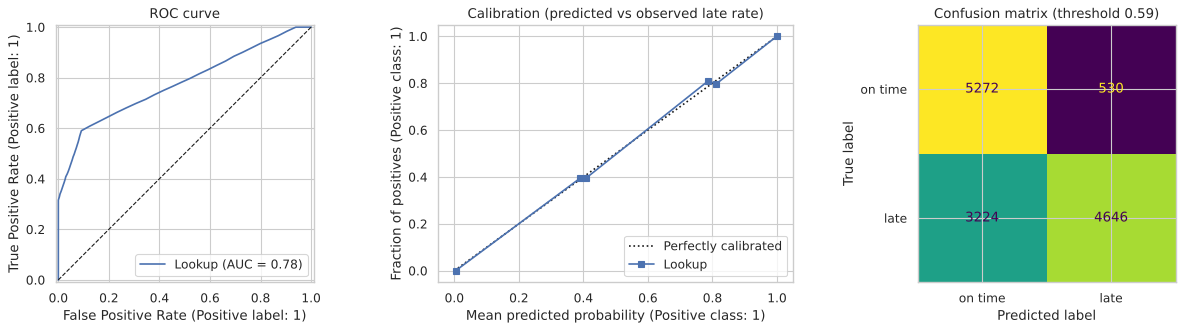

In [52]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
RocCurveDisplay.from_predictions(y_t, p_test, ax=ax[0], name=selected); ax[0].plot([0, 1], [0, 1], 'k--', lw=1); ax[0].set_title('ROC curve')
CalibrationDisplay.from_predictions(y_t, p_test, n_bins=10, ax=ax[1], name=selected); ax[1].set_title('Calibration (predicted vs observed late rate)')
ConfusionMatrixDisplay.from_predictions(y_t, p_test >= thr, ax=ax[2], display_labels=['on time', 'late'], colorbar=False)
ax[2].set_title(f'Confusion matrix (threshold {thr:.2f})')
plt.tight_layout()

In [53]:
res = pd.DataFrame({'y': y_t, 'p': p_test, 'mode': test['Shipping Mode'].astype(str).to_numpy(),
                    'quarter': test['Order Date'].dt.to_period('Q').astype(str).to_numpy()})
res['correct'] = (res.p >= thr) == (res.y == 1)
mode_eval = res.groupby('mode').agg(orders=('y', 'size'), actual_late_rate=('y', 'mean'), mean_predicted=('p', 'mean'), accuracy=('correct', 'mean'))
display(mode_eval)


def quarter_metrics(g):
    return pd.Series({'orders': len(g), 'AUC': roc_auc_score(g.y, g.p) if g.y.nunique() == 2 else np.nan,
                      'log_loss': log_loss(g.y, g.p, labels=[0, 1]), 'late_rate': g.y.mean()})


display(pd.DataFrame({q: quarter_metrics(g) for q, g in res.groupby('quarter')}).T)

,orders,actual_late_rate,mean_predicted,accuracy
mode,,,,
First Class,2074,1.000,1.000,1.000
Same Day,760,0.539,0.539,1.000
Second Class,2692,0.803,0.799,0.803
Standard Class,8146,0.396,0.399,0.604


,orders,AUC,log_loss,late_rate
2017Q2,601.000,0.754,0.516,0.576
2017Q3,"5,028.000",0.781,0.496,0.574
2017Q4,"6,006.000",0.777,0.499,0.573
2018Q1,"2,037.000",0.779,0.495,0.587


In [54]:
pi = permutation_importance(final, X_test, y_test, scoring='neg_log_loss', n_repeats=10, random_state=SEED)
display(pd.DataFrame({'log-loss increase when shuffled': pi.importances_mean, 'std': pi.importances_std}, index=FEATURES)
        .sort_values('log-loss increase when shuffled', ascending=False))

# sanity: the same pipeline trained on a shuffled target must not beat chance
shuffled = build(selected, optuna.trial.FixedTrial(studies[selected].best_params)).fit(
    fit_rows[FEATURES], fit_rows[TARGET].sample(frac=1, random_state=SEED).to_numpy())
print('AUC on test with shuffled training target:', round(roc_auc_score(y_t, shuffled.predict_proba(X_test)[:, 1]), 4))

,log-loss increase when shuffled,std
Shipping Mode,1.255,0.032
order_hour,0.152,0.005


AUC on test with shuffled training target: 0.5168


Use the per-mode table, the quarterly stability table and permutation importance to judge whether the model is right for the right reasons. The shuffled-target AUC should be near 0.5; this is a sanity check, not proof that every possible source of leakage is absent. Quarterly AUC is undefined when a quarter contains one class only.

**Result.** Calibration is exact per mode (e.g. Second Class 0.799 predicted vs 0.803 observed) and quarterly AUC is stable (0.754-0.781; 2017Q2 has only 601 orders). Permutation-importance magnitudes are inflated because the lookup gives near-0/1 probabilities; use them for ranking only. The shuffled-target AUC of 0.517 is not a leak: after shuffling, cells keep tiny random probability differences, and because the true late rate differs so strongly by mode (First Class 100 %), those differences move AUC slightly off 0.5.

In [55]:
# NOTE: the saved object contains LookupClassifier / add_cross defined in this notebook;
# keep those definitions importable (e.g. paste them into a module) when loading the file elsewhere.
joblib.dump({'model': final, 'model_name': selected, 'features': FEATURES, 'target': TARGET, 'threshold': thr,
             'embargo_days': EMBARGO_DAYS}, 'late_risk_model.joblib')
print('saved late_risk_model.joblib')

saved late_risk_model.joblib
